# Tipos de inicialização: comparação entre os quatro geradores

Comparamos histórico zero, constante positiva, constante negativa, uniforme e estacionário conjunto. Em seguida examinamos cossenos completos, meios ciclos e quartos de ciclo, com e sem soma escalar, variando a memória e o período em subseções próprias.

## Gabarito dos gráficos: o que aparece em cada posição

Em cada condição, o **primeiro bloco** mostra apenas o histórico inicial do mecanismo 0.
O **segundo bloco** mostra o histórico seguido pela série gerada, para os mecanismos 0, 1 e 2.
As cinco colunas mantêm a mesma ordem em todos os casos:

| Bloco e posição | Coluna 1: AST original | Coluna 2: Jacobiano | Coluna 3: Shao–Wu, `tanh` nos fatores | Coluna 4: Shao–Wu, `tanh` após o produto | Coluna 5: Heaps |
|---|---|---|---|---|---|
| Primeiro bloco: única linha, histórico em escala linear | Histórico do mecanismo 0 | Histórico do mecanismo 0 | Histórico do mecanismo 0 | Histórico do mecanismo 0 | Histórico do mecanismo 0 |
| Segundo bloco: linha 1 | Mecanismo 0: histórico + 3 trajetórias | Mecanismo 0: histórico + 3 trajetórias | Mecanismo 0: histórico + 3 trajetórias | Mecanismo 0: histórico + 3 trajetórias | Mecanismo 0: histórico + 3 trajetórias |
| Segundo bloco: linha 2 | Mecanismo 1: histórico + 3 trajetórias | Mecanismo 1: histórico + 3 trajetórias | Mecanismo 1: histórico + 3 trajetórias | Mecanismo 1: histórico + 3 trajetórias | Mecanismo 1: histórico + 3 trajetórias |
| Segundo bloco: linha 3 | Mecanismo 2: histórico + 3 trajetórias | Mecanismo 2: histórico + 3 trajetórias | Mecanismo 2: histórico + 3 trajetórias | Mecanismo 2: histórico + 3 trajetórias | Mecanismo 2: histórico + 3 trajetórias |

Os índices dos mecanismos identificam exemplos predeterminados em cada família. A equação
associada ao mesmo índice pode ser diferente entre famílias. Os dois modos do Shao–Wu pertencem
à mesma família, por isso quatro famílias ocupam cinco colunas.

| Elemento visual | Significado |
|---|---|
| Azul `r0`, laranja `r1`, verde `r2` | Três trajetórias do mesmo mecanismo. Cada uma tem sua sequência de ruído futuro; as condições comparadas reutilizam essa sequência. |
| Histórico em $t\leq0$ | Valores fornecidos antes de iniciar a execução da equação. Na grade de trajetórias, aparecem pontilhados. |
| Série em $t\geq1$ | Valores calculados pela equação com as inovações aleatórias. As linhas contínuas mostram a saída gerada. |
| Faixa cinza | Os últimos $p$ valores iniciais que formam o estado de lags usado pela equação. A largura inclui meia unidade de cada lado das amostras discretas. |
| `p` e `N` no título do histórico | `p` é o maior lag exigido; `N` é a quantidade de amostras do histórico exibido. Um histórico cíclico pode ter $N>p$. |
| Ponto em $t=0$ quando $N=1$ | Histórico com uma única amostra. No caso zero, o ponto está em $(0,0)$. Históricos idênticos das três trajetórias se sobrepõem. |
| `Not applicable` | A condição está fora das possibilidades ou do domínio certificado daquele gerador; a tabela informa o motivo. |
| Escala `symlog` da grade de trajetórias | Linear perto de zero e logarítmica nas magnitudes maiores, preservando os sinais. Cada painel ajusta seus limites; compare os valores dos eixos. |

Nos gráficos de métricas, quando presentes, a posição tem este significado:

| Posição horizontal | Métrica mostrada |
|---|---|
| Esquerda | Percentual de explosões. |
| Centro | Percentual de trajetórias classificadas como quase zero. |
| Direita | Percentual de trajetórias com cauda persistentemente plana. |

Nas seções básicas, o eixo horizontal desses gráficos é o horizonte (96, 192 ou 384).
Ao final de cada seção cíclica, o gráfico agregado compara as combinações de memória e período
no horizonte 384. As cores desses gráficos identificam **métodos**, conforme a legenda.


## Protocolo e leitura dos gráficos

Cada seção corresponde a **uma forma de inicialização**. Dentro dela comparamos AST original,
Jacobiano, Shao–Wu e Heaps. Os dois modos do Shao–Wu ocupam colunas separadas para que suas
diferenças sejam visíveis: `tanh` nos fatores e `tanh` depois do produto.

- Estudos básicos: **32 mecanismos × 3 trajetórias por condição**. Estudos cíclicos:
  **12 mecanismos × 3 trajetórias por condição**, com mais combinações de lag, período e recorte.
  Usamos um canal, pois o construtor Jacobiano atual é univariado. Horizontes: **96, 192 e 384**.
- A equação fica fixa dentro de cada banco de mecanismos. Os casos de inicialização reutilizam
  **os mesmos valores de inovação futura**, e cada trajetória recebe um fluxo local reprodutível.
  As sementes iguais entre famílias identificam amostras; cada família tem seu próprio mecanismo.
- O desvio padrão da inovação é 0,05. AST original, Shao–Wu e Heaps usam ruído gaussiano;
  Jacobiano usa ruído uniforme limitado por $\sqrt{3}\,0{,}05$. Diferenças entre famílias também
  refletem essas leis e seus diferentes vocabulários.
- Histórico inicial em $t\leq0$; primeira observação gerada em $t=1$. A saída avaliada contém
  somente os **384 valores solicitados**, sem descartar passos de aquecimento. As linhas pontilhadas
  mostram o histórico, e a faixa cinza marca os últimos $p$ valores usados pela equação.
  Os gráficos usam os mecanismos 0, 1 e 2 definidos antes dos resultados, com **as três trajetórias**.
- Explosão: valor não finito ou módulo acima de $10^6$. A primeira falha encerra a trajetória
  e permanece no denominador. Quase zero: últimos 48 valores dentro de $[-0{,}15,0{,}15]$.
  Cauda persistentemente plana: as duas janelas finais de 24 passos e seu intervalo conjunto
  de 48 passos satisfazem a tolerância 0,15 do diagnóstico existente. Platô não nulo e queda de
  amplitude usam o mesmo módulo de diagnóstico. As categorias podem se sobrepor.
- Para o Jacobiano, a inicialização precisa caber na caixa certificada $[-1,1]^p$.
  Condições incompatíveis aparecem como **não aplicáveis**, com contagem explícita de tentativas
  que não foram executadas. A inicialização gaussiana estacionária conjunta está disponível no Heaps.
- As taxas descrevem estes bancos e horizontes. As três trajetórias de um mecanismo compartilham
  sua equação. Os tempos mostrados são medições descritivas desta execução, sem repetição de benchmark.

### Como o histórico cíclico é construído

Definimos $h_k=c+A\cos(2\pi k/P)$ para $k=0,\ldots,N-1$, com
$N=P$, $N=P/2$ ou $N=P/4$. **Metade e quarto são prefixos do mesmo ciclo**: conservam o período
$P$ e o espaçamento de um passo, sem preencher o trecho removido com zeros. A amostra em $k=N-1$
é posicionada em $t=0$; o extremo direito do intervalo contínuo não é amostrado.

Nos estudos de memória, o limite $L$ vale 12, 24 ou 48 e os lags das ASTs são sorteados entre
$\lceil L/2\rceil$ e $L$. Heaps tem ordem exatamente $L$. O período vale $4L$ ou $8L$,
portanto até o quarto de ciclo fornece histórico suficiente. Cada painel informa o maior lag
efetivamente usado. O gerador consulta os últimos $p$ valores do histórico; amostras anteriores
são exibidas para tornar o recorte compreensível. Aumentar $L$ também pode alterar coeficientes
e limites calculados pelos métodos: a comparação entre bancos inclui esse efeito.

A amplitude cíclica básica é $A=0{,}5$. Comparamos $c=0$ e a soma escalar $c=0{,}5$.
A curva cosseno define a **condição inicial**; a continuação é produzida pela equação sorteada
e pelo ruído. Sua periodicidade futura é um resultado observado, não uma condição imposta.

**Código reutilizável:** [initialization.py](../../src/tsfmxai/evaluation/initialization.py)
e [initialization_study.py](../../src/tsfmxai/visualization/initialization_study.py).


Os recortes de cosseno alteram a fase e os valores presentes em t=0. Nesta atualização, este notebook foi executado isoladamente; os tempos registrados são medições descritivas desta execução. As métricas de qualidade usam os fluxos locais declarados.

As colunas dos painéis seguem sempre esta ordem: **AST original, Jacobiano, Shao–Wu nos fatores, Shao–Wu após o produto, Heaps**. Essa ordem também vale para colunas marcadas como não aplicáveis. Os históricos isolados usam escala linear. Nas grades de trajetórias, a escala `symlog` é linear perto de zero e logarítmica nas magnitudes maiores, preservando valores positivos e negativos.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess, platform, importlib.metadata
from dataclasses import asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, JSON
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from tsfmxai.evaluation.initialization import (
    GROUPS, HistorySpec, InitializationStudyConfig, generator_configs,
    sample_study_mechanisms, run_history_case, run_history_pair,
)
from tsfmxai.visualization.initialization_study import (
    initialization_tables, forgetting_table, plot_history_comparison,
    plot_startup_histories, plot_case_rates, plot_pair_gaps, plot_condition_summary,
)

thread_limits = threadpool_limits(limits=1)
plt.rcParams.update({"figure.dpi": 85, "savefig.dpi": 85, "font.size": 9})
CONFIG = InitializationStudyConfig(mechanisms=32, trajectories=3, example_mechanisms=3)
SUMMARY_BLOCKS, SKIPPED_BLOCKS, DECLARATIONS = [], [], []
BANKS = {}
pd.set_option("display.max_rows", 180)
pd.set_option("display.max_columns", 24)
display(pd.Series(asdict(CONFIG), name="Configuração básica"))

def cyclic_config(lag):
    return replace(CONFIG, mechanisms=12, minimum_lag=(lag+1)//2,
                   maximum_lag=lag, heaps_fixed_order=True)

def bank(config):
    if config not in BANKS:
        BANKS[config] = {g: sample_study_mechanisms(g, config) for g in GROUPS}
    return BANKS[config]

def show_condition(block, spec, config, *, overview=True):
    mechanisms = bank(config)
    results = {g: run_history_case(g, mechanisms[g], config, spec) for g in GROUPS}
    summary, skipped = initialization_tables(results)
    if not summary.empty:
        summary.insert(0, "block", block)
        SUMMARY_BLOCKS.append(summary)
    if not skipped.empty:
        skipped.insert(0, "block", block)
        SKIPPED_BLOCKS.append(skipped)
        display(skipped.groupby(["method", "reason"], sort=False).skipped_trajectories.sum().reset_index())
    DECLARATIONS.append({"block": block, "configuration": asdict(config), "history": asdict(spec)})
    plot_startup_histories(results, block)
    plt.show()
    plot_history_comparison(results, block, config)
    plt.show()
    if not summary.empty:
        columns = ["method", "trajectories", "explosions_pct", "near_zero_pct", "persistent_flat_pct",
                   "flat_nonzero_pct", "minimum_actual_lag", "maximum_actual_lag", "mean_simulation_seconds"]
        display(summary.loc[summary.horizon == max(config.horizons), columns].round(4))
    if overview:
        plot_case_rates(results, block, config)
        plt.show()
    return results

def show_pair(block, left, right, config):
    mechanisms = bank(config)
    results = {g: run_history_pair(g, mechanisms[g], config, left, right, name=block) for g in GROUPS}
    summary = forgetting_table(results)
    if not summary.empty:
        summary.insert(0, "block", block)
        SUMMARY_BLOCKS.append(summary)
    skipped = pd.DataFrame([r for result in results.values() for r in result["skipped"]])
    if not skipped.empty:
        skipped.insert(0, "block", block)
        SKIPPED_BLOCKS.append(skipped)
        display(skipped.groupby(["method", "reason"], sort=False).skipped_trajectories.sum().reset_index())
    DECLARATIONS.append({"block": block, "configuration": asdict(config),
                         "left_history": asdict(left), "right_history": asdict(right)})
    plot_history_comparison(results, block, config)
    plt.show()
    plot_pair_gaps(results, block, config)
    plt.show()
    if not summary.empty:
        display(summary.loc[summary.horizon == max(config.horizons)].round(6))
    checks = [r["weighted_bound_passed"] for v in results.values() for r in v["rows"]
              if r["horizon"] == max(config.horizons) and r["weighted_bound_passed"] is not None]
    assert all(checks), "Falha no limite pareado do Jacobiano."
    return results

STUDY = 'starting_values'
QUESTION = 'Como a forma do histórico inicial altera a qualidade das trajetórias de cada gerador?'
HYPOTHESIS = 'Históricos diferentes alteram transientes e taxas de falha de forma dependente da equação; controle de amplitude e esquecimento têm papéis distintos.'
NOTEBOOK_NAME = '1_starting_values.ipynb'

mechanisms                                          32
trajectories                                         3
mechanism_seed                              2026102601
trajectory_seed                             2026102602
horizons                                (96, 192, 384)
innovation_std                                    0.05
explosion_limit                              1000000.0
near_zero_radius                                  0.15
tail_steps                                          48
flat_tolerance                                    0.15
window_steps                                        24
constant_value                                     0.5
uniform_radius                                     1.0
magnitude_scales        (0.0, 0.1, 0.5, 1.0, 2.0, 4.0)
forgetting_tolerance                          0.000001
forgetting_tail                                     24
minimum_lag                                          1
maximum_lag                                         12
heaps_fixe

**O que foi feito:** Definimos sementes, critérios e bancos de mecanismos reutilizados entre condições. As funções de apresentação mantêm todas as variantes lado a lado e registram cada configuração.

## 1. Histórico zero

Todos os valores passados são zero. Os métodos são avaliados abaixo com o mesmo protocolo.

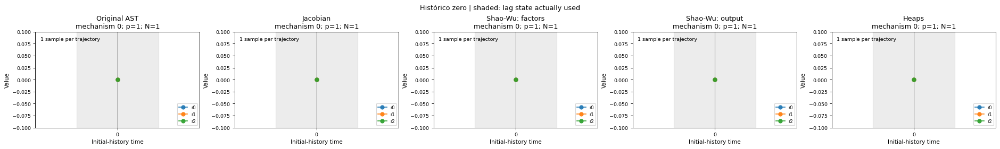

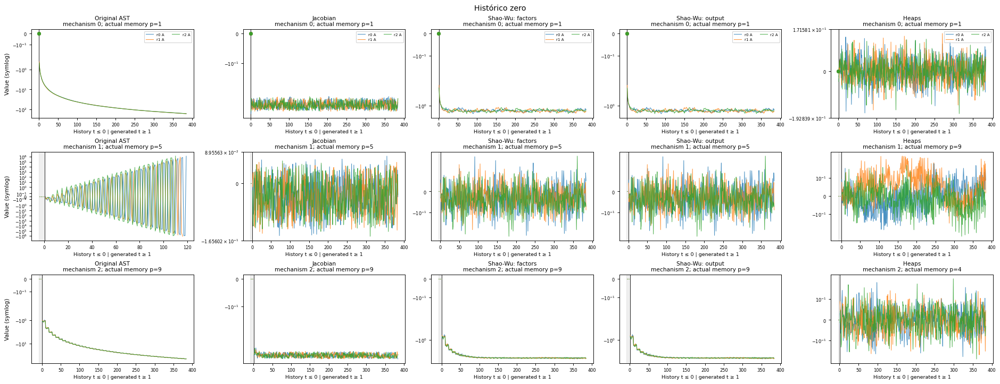

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0065
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0120
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0115
11,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0091
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0121


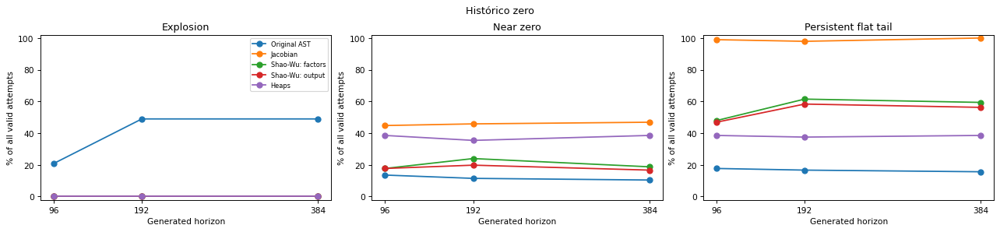

In [2]:
result = show_condition('Histórico zero', HistorySpec('zero', 'zero'), CONFIG)

**O que foi feito:** O primeiro gráfico mostra o histórico inicial; o segundo mostra três mecanismos e todas as suas trajetórias. A tabela e o terceiro gráfico comparam os diagnósticos entre geradores.

## 2. Constante positiva

Todos os valores passados são +0,5. Os métodos são avaliados abaixo com o mesmo protocolo.

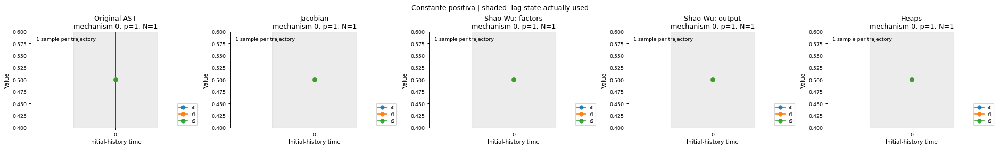

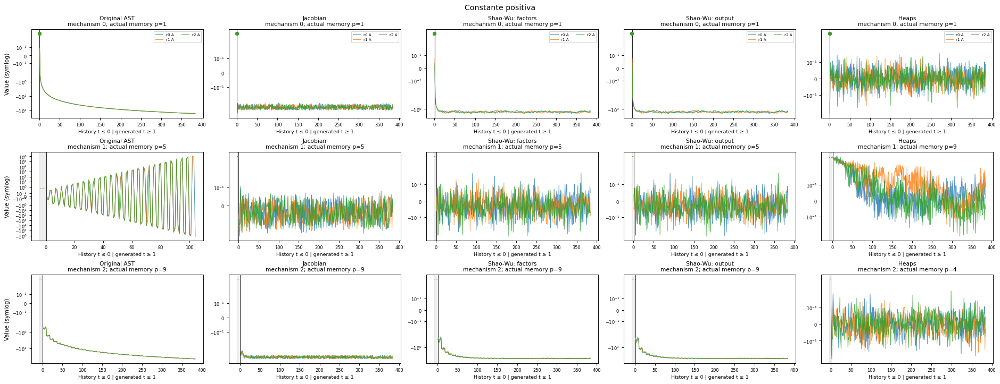

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0047
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0087
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0084
11,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0085
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0127


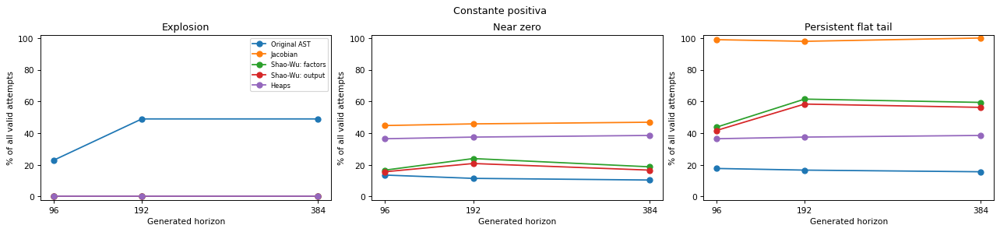

In [3]:
result = show_condition('Constante positiva', HistorySpec('positive constant', 'constant', offset=.5), CONFIG)

**O que foi feito:** O primeiro gráfico mostra o histórico inicial; o segundo mostra três mecanismos e todas as suas trajetórias. A tabela e o terceiro gráfico comparam os diagnósticos entre geradores.

## 3. Constante negativa

Todos os valores passados são −0,5. Os métodos são avaliados abaixo com o mesmo protocolo.

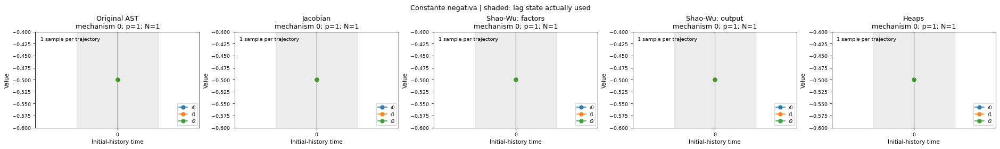

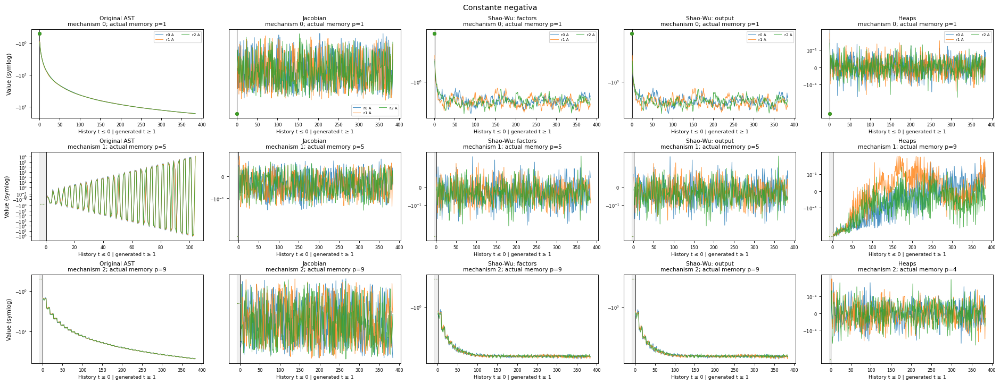

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,50.0,10.4167,15.6250,0.0000,1,12,0.0048
5,Jacobian,96,0.0,46.8750,100.0000,35.4167,1,12,0.0087
8,Shao-Wu: factors,96,0.0,18.7500,59.3750,27.0833,1,12,0.0082
11,Shao-Wu: output,96,0.0,16.6667,56.2500,30.2083,1,12,0.0082
14,Heaps,96,0.0,38.5417,38.5417,0.0000,1,12,0.0115


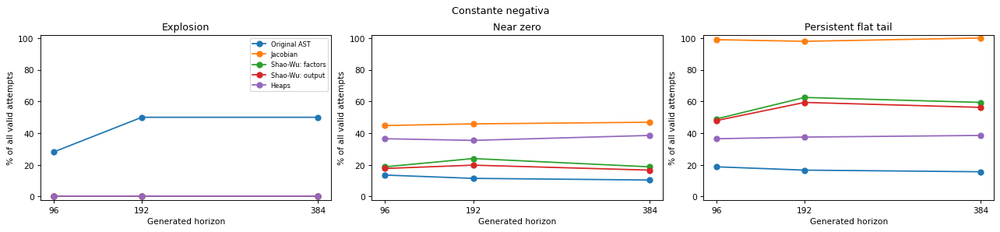

In [4]:
result = show_condition('Constante negativa', HistorySpec('negative constant', 'constant', offset=-.5), CONFIG)

**O que foi feito:** O primeiro gráfico mostra o histórico inicial; o segundo mostra três mecanismos e todas as suas trajetórias. A tabela e o terceiro gráfico comparam os diagnósticos entre geradores.

## 4. Uniforme aleatório

Cada valor passado é sorteado uniformemente em [−1,1]. Os métodos são avaliados abaixo com o mesmo protocolo.

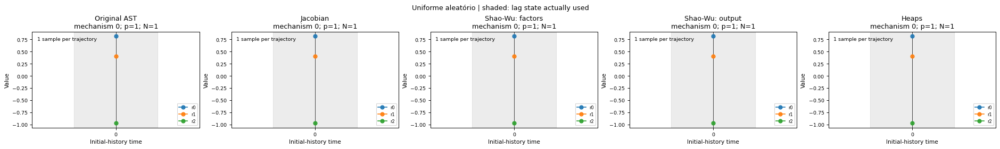

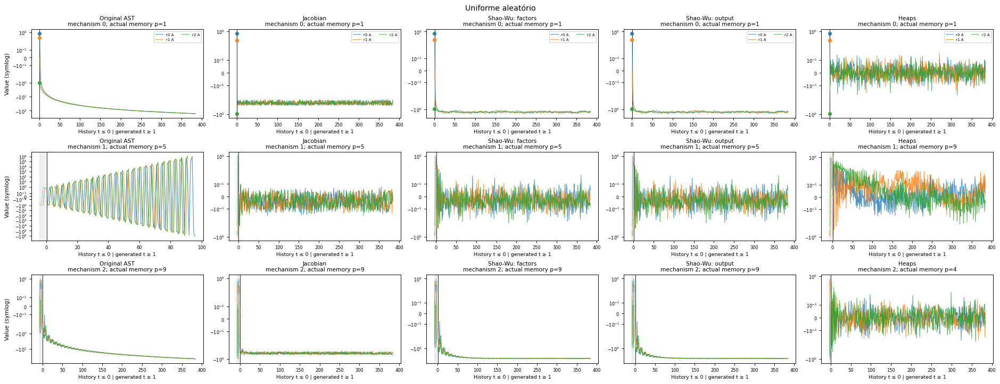

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0046
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0096
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0082
11,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0082
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0113


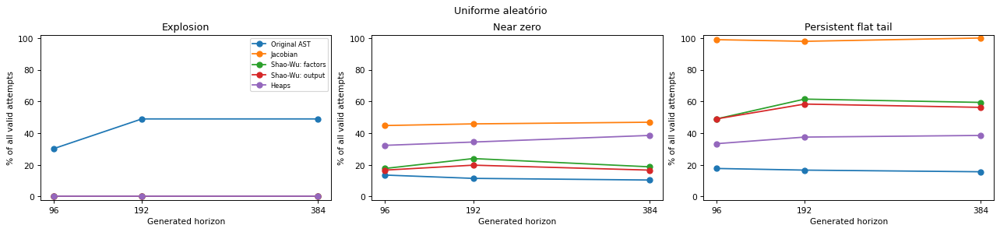

In [5]:
result = show_condition('Uniforme aleatório', HistorySpec('uniform', 'uniform', amplitude=1.), CONFIG)

**O que foi feito:** O primeiro gráfico mostra o histórico inicial; o segundo mostra três mecanismos e todas as suas trajetórias. A tabela e o terceiro gráfico comparam os diagnósticos entre geradores.

## 5. Distribuição estacionária conjunta

Heaps sorteia o histórico gaussiano conjunto da própria equação. As demais famílias aparecem como não aplicáveis nesta seção. Os métodos são avaliados abaixo com o mesmo protocolo.

,method,reason,skipped_trajectories
0,Original AST,Joint stationary initializer unavailable,96
1,Jacobian,Joint stationary initializer unavailable,96
2,Shao-Wu: factors,Joint stationary initializer unavailable,96
3,Shao-Wu: output,Joint stationary initializer unavailable,96


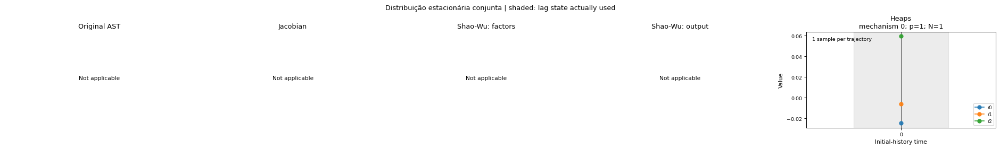

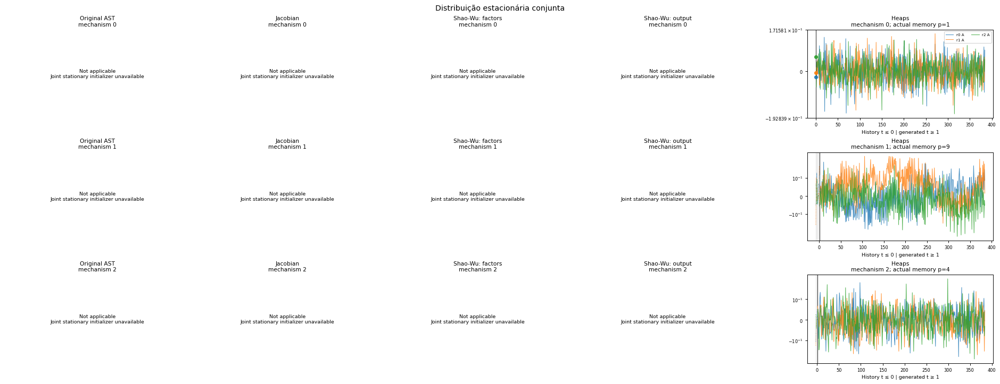

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Heaps,96,0.0,38.5417,38.5417,0.0,1,12,0.0122


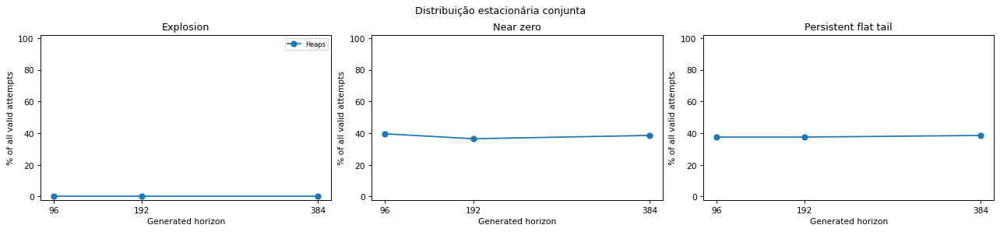

In [6]:
result = show_condition('Distribuição estacionária conjunta', HistorySpec('stationary joint', 'stationary'), CONFIG)

**O que foi feito:** O primeiro gráfico mostra o histórico inicial; o segundo mostra três mecanismos e todas as suas trajetórias. A tabela e o terceiro gráfico comparam os diagnósticos entre geradores.

## 6. Cosseno: ciclo completo

Amplitude A=0,5; deslocamento c=0.0. O histórico contém 1 do ciclo, sempre com espaçamento unitário.

### Memória até 12 passos

As ASTs usam lags entre 6 e 12; Heaps tem ordem 12. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=48: histórico de 48 amostras

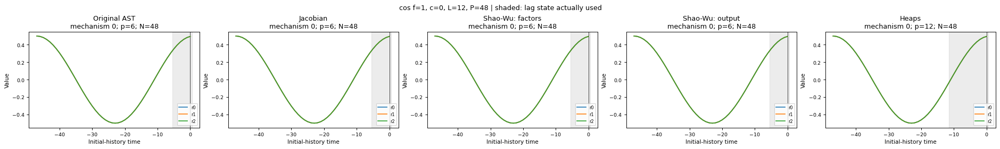

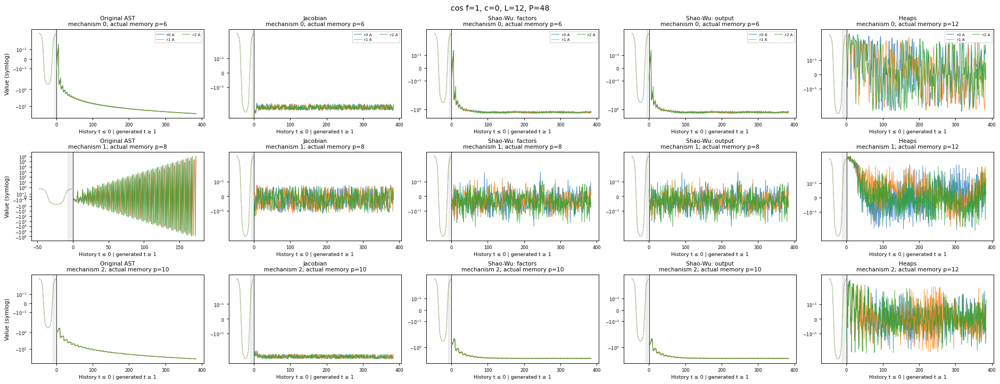

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,8.3333,13.8889,0.0000,6,12,0.0052
5,Jacobian,36,0.0000,63.8889,100.0000,25.0000,6,12,0.0116
8,Shao-Wu: factors,36,0.0000,19.4444,47.2222,16.6667,6,12,0.0126
11,Shao-Wu: output,36,0.0000,19.4444,44.4444,16.6667,6,12,0.0098
14,Heaps,36,0.0000,2.7778,5.5556,0.0000,12,12,0.0163


In [7]:
result = show_condition('cos f=1, c=0, L=12, P=48', HistorySpec('cos f=1, c=0, L=12, P=48', 'cosine', .5, 0.0, 48, 1.0), cyclic_config(12), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=96: histórico de 96 amostras

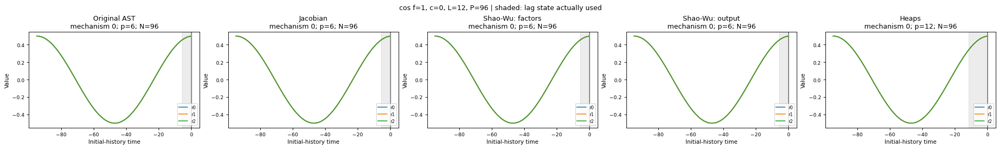

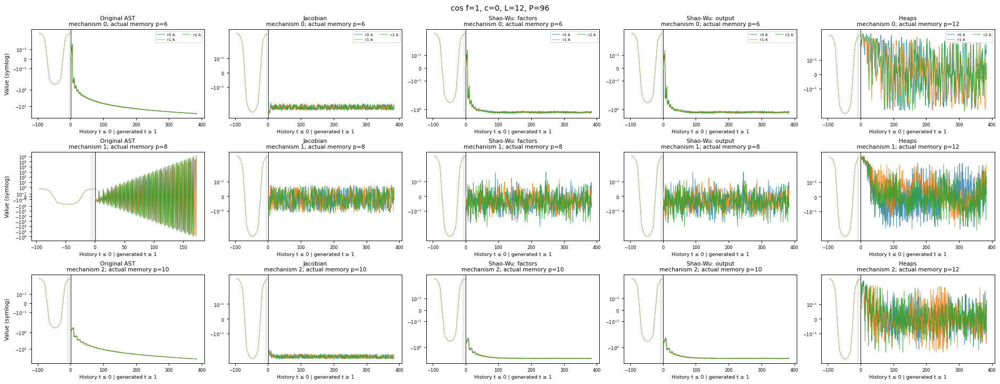

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,8.3333,13.8889,0.0000,6,12,0.0054
5,Jacobian,36,0.0000,63.8889,100.0000,25.0000,6,12,0.0089
8,Shao-Wu: factors,36,0.0000,19.4444,47.2222,16.6667,6,12,0.0085
11,Shao-Wu: output,36,0.0000,19.4444,44.4444,16.6667,6,12,0.0084
14,Heaps,36,0.0000,2.7778,5.5556,0.0000,12,12,0.0152


In [8]:
result = show_condition('cos f=1, c=0, L=12, P=96', HistorySpec('cos f=1, c=0, L=12, P=96', 'cosine', .5, 0.0, 96, 1.0), cyclic_config(12), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

### Memória até 24 passos

As ASTs usam lags entre 12 e 24; Heaps tem ordem 24. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=96: histórico de 96 amostras

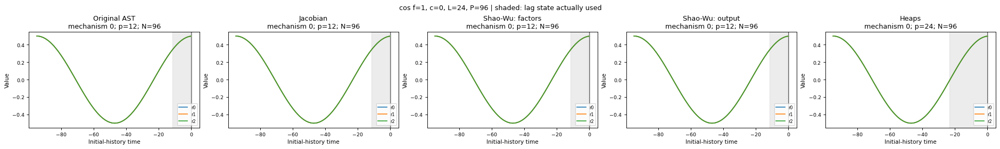

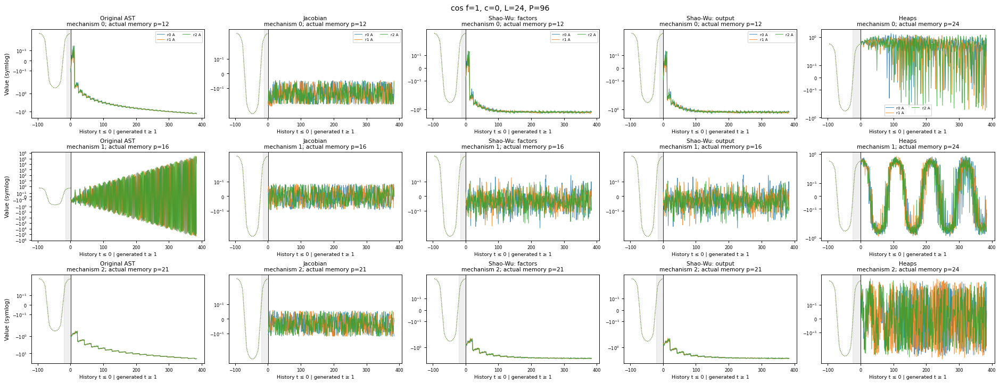

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0068
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0126
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0094
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0096
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0249


In [9]:
result = show_condition('cos f=1, c=0, L=24, P=96', HistorySpec('cos f=1, c=0, L=24, P=96', 'cosine', .5, 0.0, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=192: histórico de 192 amostras

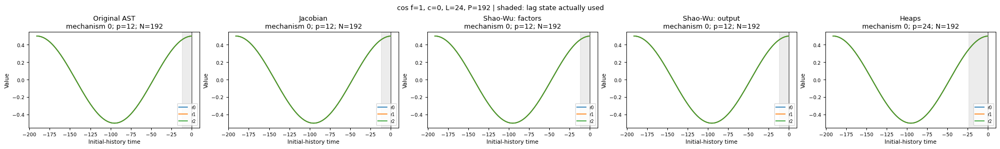

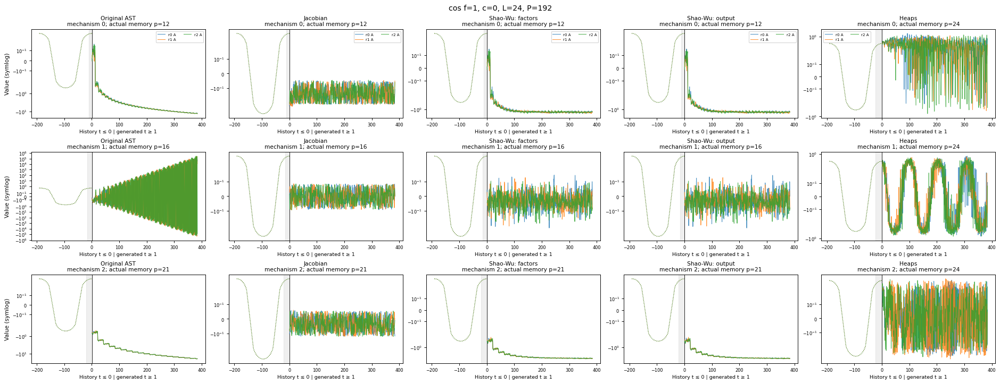

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0065
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0094
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0107
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0083
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0256


In [10]:
result = show_condition('cos f=1, c=0, L=24, P=192', HistorySpec('cos f=1, c=0, L=24, P=192', 'cosine', .5, 0.0, 192, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

### Memória até 48 passos

As ASTs usam lags entre 24 e 48; Heaps tem ordem 48. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=192: histórico de 192 amostras

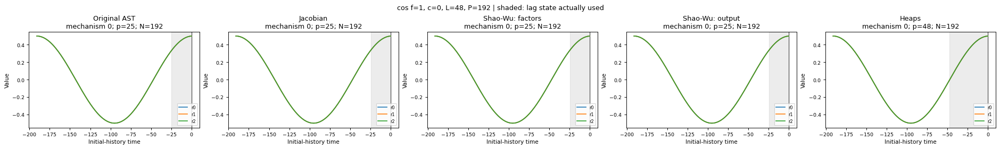

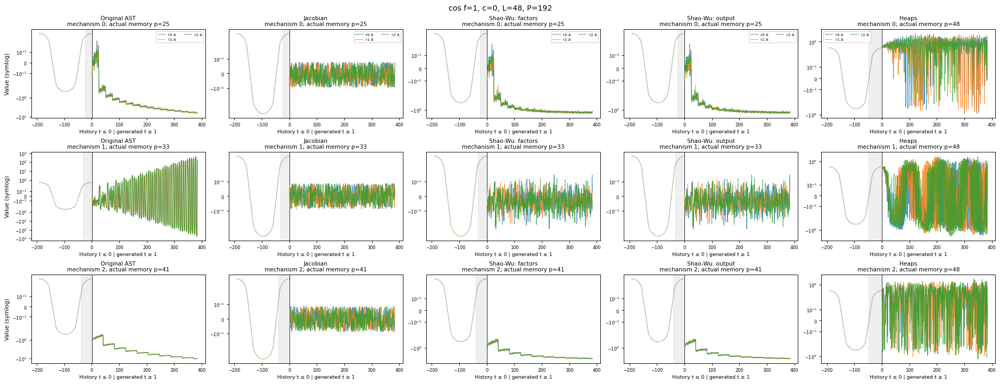

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,16.6667,8.3333,11.1111,0.0000,25,48,0.0085
5,Jacobian,36,0.0000,100.0000,100.0000,0.0000,25,48,0.0095
8,Shao-Wu: factors,36,0.0000,16.6667,36.1111,8.3333,25,48,0.0097
11,Shao-Wu: output,36,0.0000,13.8889,30.5556,8.3333,25,48,0.0100
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,48,48,0.0508


In [11]:
result = show_condition('cos f=1, c=0, L=48, P=192', HistorySpec('cos f=1, c=0, L=48, P=192', 'cosine', .5, 0.0, 192, 1.0), cyclic_config(48), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=384: histórico de 384 amostras

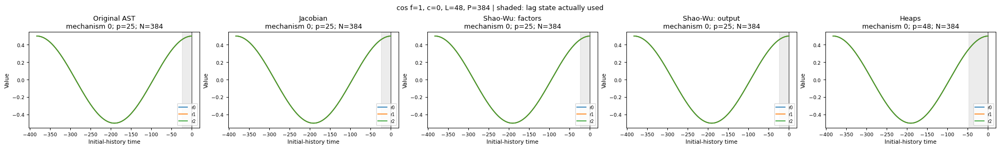

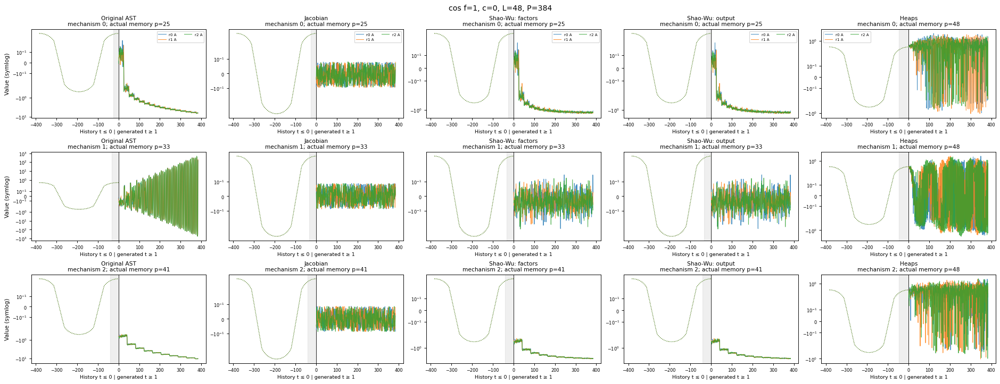

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,16.6667,8.3333,11.1111,0.0000,25,48,0.0097
5,Jacobian,36,0.0000,100.0000,100.0000,0.0000,25,48,0.0119
8,Shao-Wu: factors,36,0.0000,16.6667,36.1111,8.3333,25,48,0.0156
11,Shao-Wu: output,36,0.0000,11.1111,30.5556,8.3333,25,48,0.0098
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,48,48,0.0499


In [12]:
result = show_condition('cos f=1, c=0, L=48, P=384', HistorySpec('cos f=1, c=0, L=48, P=384', 'cosine', .5, 0.0, 384, 1.0), cyclic_config(48), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

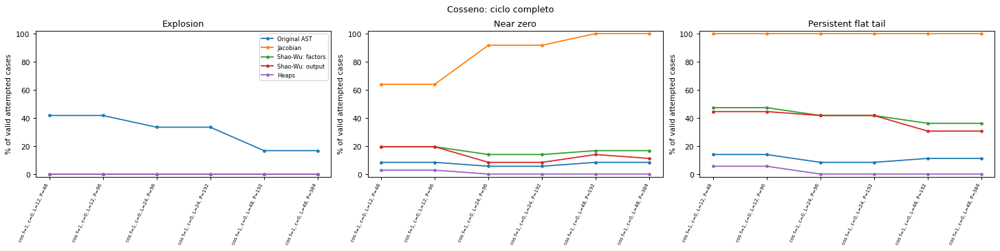

In [13]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Cosseno: ciclo completo')
plt.show()

**O que foi feito:** Comparamos os seis pares de memória e período desta inicialização, mantendo os métodos separados nas curvas.

## 7. Cosseno: primeira metade

Amplitude A=0,5; deslocamento c=0.0. O histórico contém 0.5 do ciclo, sempre com espaçamento unitário.

### Memória até 12 passos

As ASTs usam lags entre 6 e 12; Heaps tem ordem 12. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=48: histórico de 24 amostras

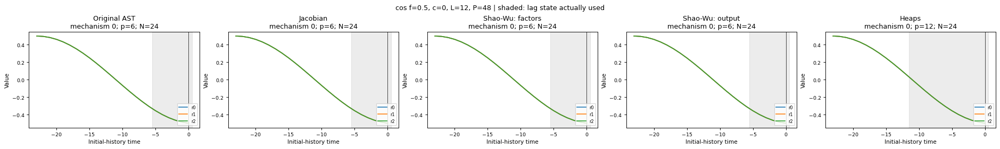

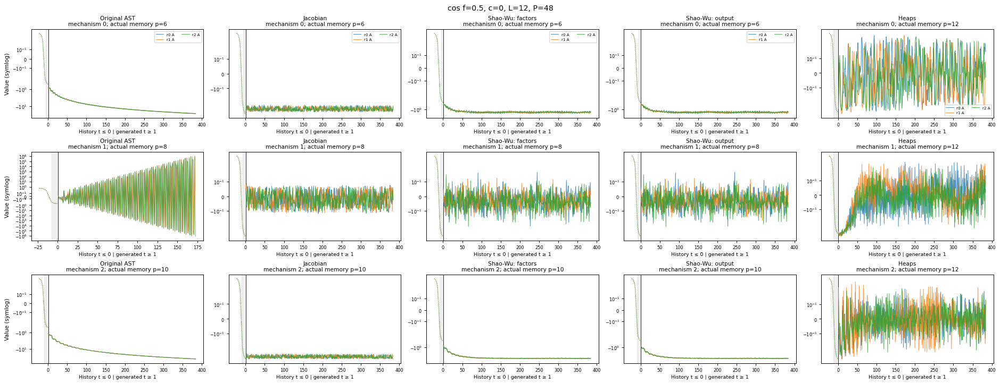

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,8.3333,13.8889,0.0000,6,12,0.0064
5,Jacobian,36,0.0000,63.8889,100.0000,25.0000,6,12,0.0109
8,Shao-Wu: factors,36,0.0000,19.4444,47.2222,16.6667,6,12,0.0105
11,Shao-Wu: output,36,0.0000,19.4444,44.4444,16.6667,6,12,0.0095
14,Heaps,36,0.0000,2.7778,2.7778,0.0000,12,12,0.0177


In [14]:
result = show_condition('cos f=0.5, c=0, L=12, P=48', HistorySpec('cos f=0.5, c=0, L=12, P=48', 'cosine', .5, 0.0, 48, 0.5), cyclic_config(12), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=96: histórico de 48 amostras

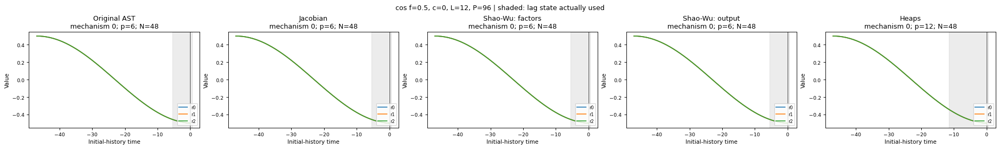

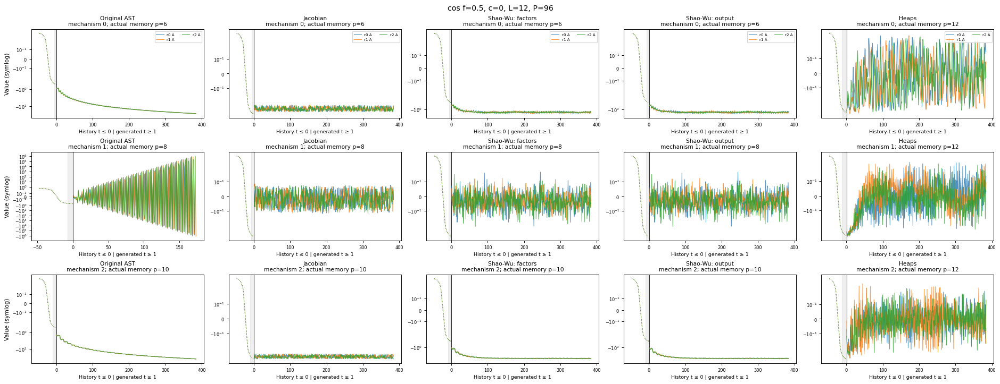

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,8.3333,13.8889,0.0000,6,12,0.0066
5,Jacobian,36,0.0000,63.8889,100.0000,25.0000,6,12,0.0102
8,Shao-Wu: factors,36,0.0000,19.4444,47.2222,16.6667,6,12,0.0094
11,Shao-Wu: output,36,0.0000,19.4444,44.4444,16.6667,6,12,0.0114
14,Heaps,36,0.0000,2.7778,2.7778,0.0000,12,12,0.0233


In [15]:
result = show_condition('cos f=0.5, c=0, L=12, P=96', HistorySpec('cos f=0.5, c=0, L=12, P=96', 'cosine', .5, 0.0, 96, 0.5), cyclic_config(12), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

### Memória até 24 passos

As ASTs usam lags entre 12 e 24; Heaps tem ordem 24. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=96: histórico de 48 amostras

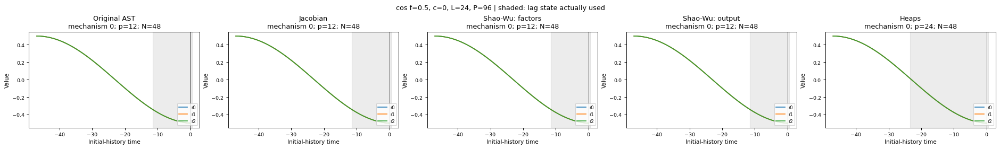

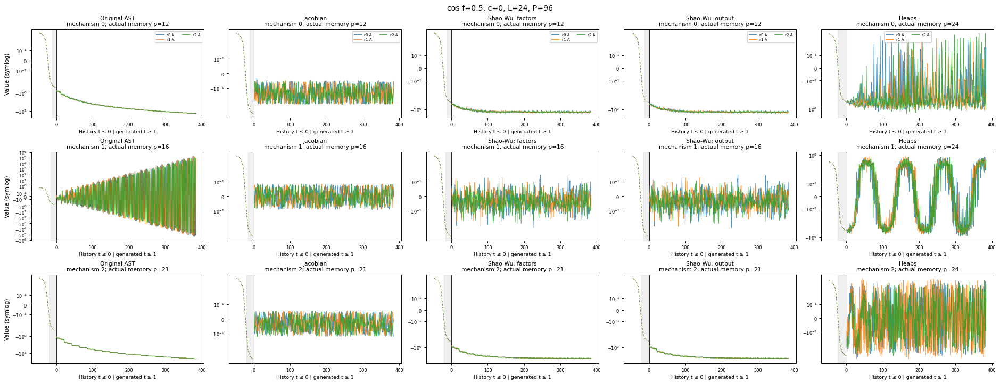

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0113
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0114
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0101
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0097
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0276


In [16]:
result = show_condition('cos f=0.5, c=0, L=24, P=96', HistorySpec('cos f=0.5, c=0, L=24, P=96', 'cosine', .5, 0.0, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=192: histórico de 96 amostras

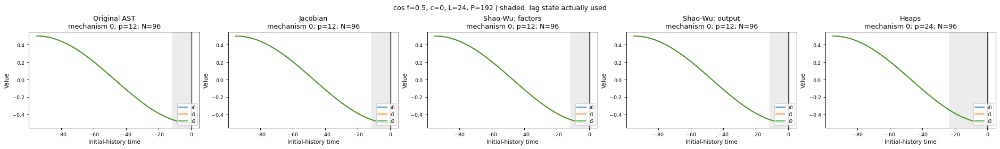

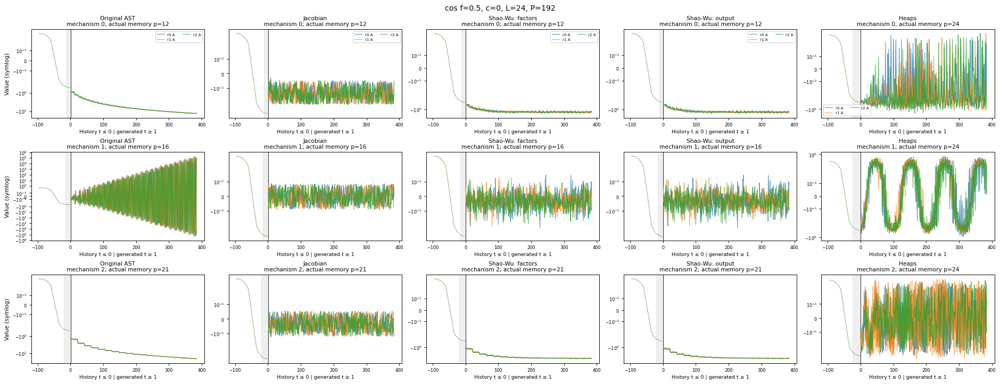

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0082
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0105
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0094
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0098
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0298


In [17]:
result = show_condition('cos f=0.5, c=0, L=24, P=192', HistorySpec('cos f=0.5, c=0, L=24, P=192', 'cosine', .5, 0.0, 192, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

### Memória até 48 passos

As ASTs usam lags entre 24 e 48; Heaps tem ordem 48. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=192: histórico de 96 amostras

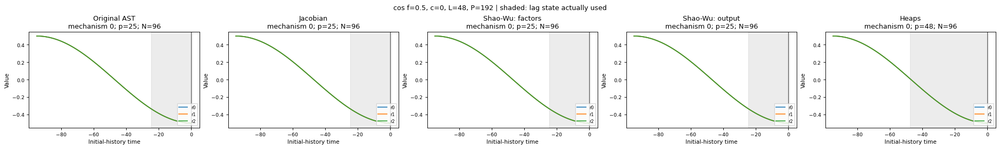

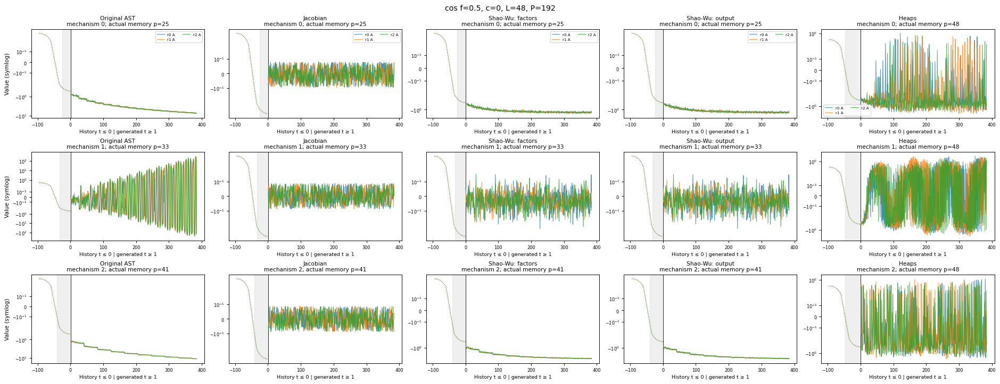

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,16.6667,8.3333,11.1111,0.0000,25,48,0.0092
5,Jacobian,36,0.0000,100.0000,100.0000,0.0000,25,48,0.0106
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,25,48,0.0099
11,Shao-Wu: output,36,0.0000,8.3333,38.8889,13.8889,25,48,0.0105
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,48,48,0.0557


In [18]:
result = show_condition('cos f=0.5, c=0, L=48, P=192', HistorySpec('cos f=0.5, c=0, L=48, P=192', 'cosine', .5, 0.0, 192, 0.5), cyclic_config(48), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=384: histórico de 192 amostras

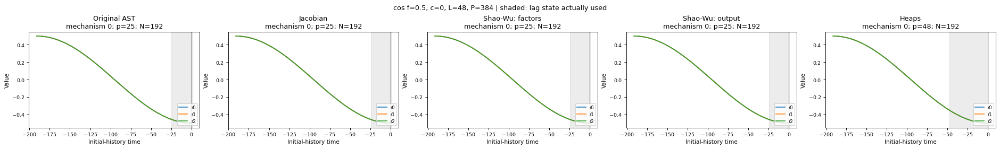

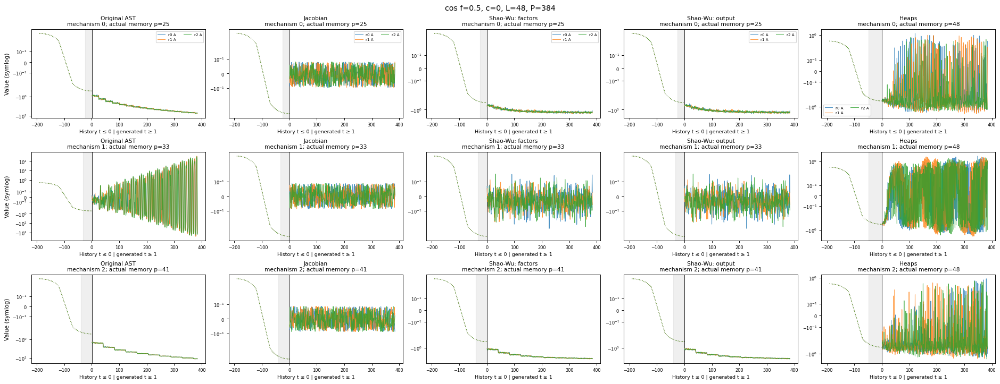

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,16.6667,8.3333,11.1111,0.0000,25,48,0.0097
5,Jacobian,36,0.0000,100.0000,100.0000,0.0000,25,48,0.0138
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,25,48,0.0123
11,Shao-Wu: output,36,0.0000,8.3333,38.8889,13.8889,25,48,0.0103
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,48,48,0.0556


In [19]:
result = show_condition('cos f=0.5, c=0, L=48, P=384', HistorySpec('cos f=0.5, c=0, L=48, P=384', 'cosine', .5, 0.0, 384, 0.5), cyclic_config(48), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

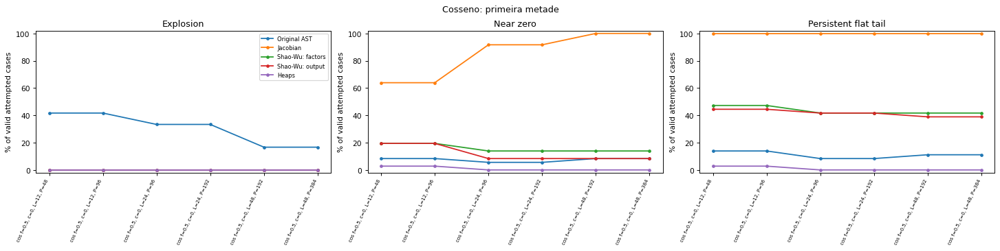

In [20]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Cosseno: primeira metade')
plt.show()

**O que foi feito:** Comparamos os seis pares de memória e período desta inicialização, mantendo os métodos separados nas curvas.

## 8. Cosseno: primeiro quarto

Amplitude A=0,5; deslocamento c=0.0. O histórico contém 0.25 do ciclo, sempre com espaçamento unitário.

### Memória até 12 passos

As ASTs usam lags entre 6 e 12; Heaps tem ordem 12. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=48: histórico de 12 amostras

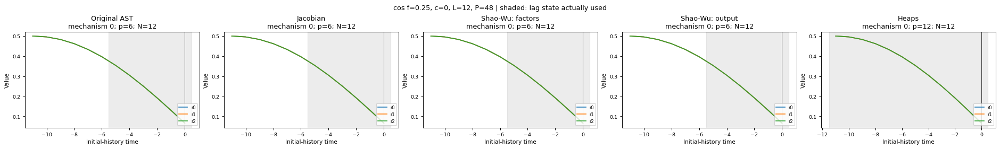

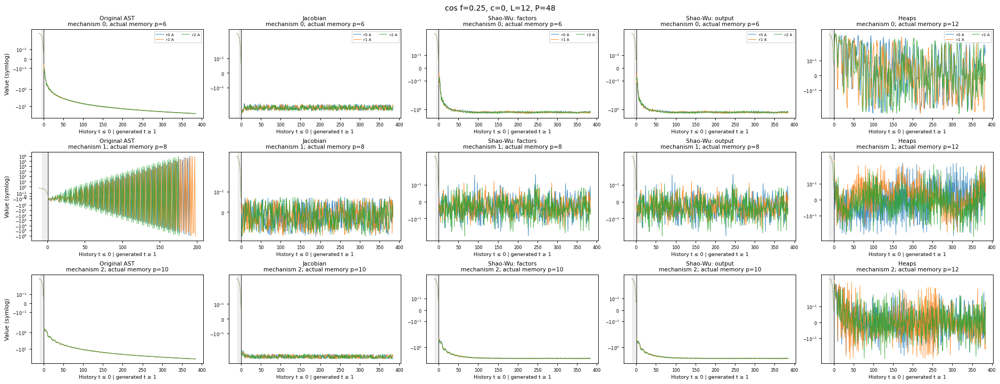

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,8.3333,13.8889,0.0000,6,12,0.0069
5,Jacobian,36,0.0000,63.8889,100.0000,25.0000,6,12,0.0156
8,Shao-Wu: factors,36,0.0000,19.4444,47.2222,16.6667,6,12,0.0109
11,Shao-Wu: output,36,0.0000,19.4444,44.4444,16.6667,6,12,0.0097
14,Heaps,36,0.0000,2.7778,5.5556,0.0000,12,12,0.0188


In [21]:
result = show_condition('cos f=0.25, c=0, L=12, P=48', HistorySpec('cos f=0.25, c=0, L=12, P=48', 'cosine', .5, 0.0, 48, 0.25), cyclic_config(12), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=96: histórico de 24 amostras

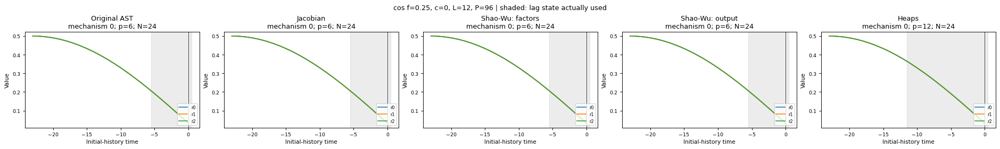

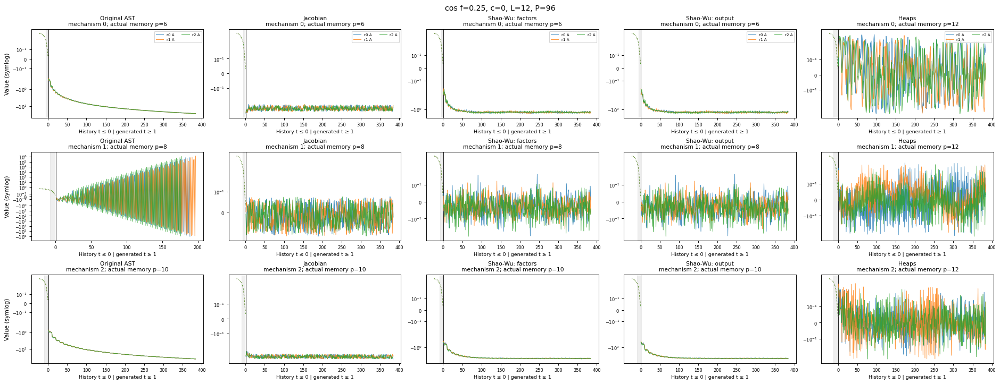

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,8.3333,13.8889,0.0000,6,12,0.0067
5,Jacobian,36,0.0000,63.8889,100.0000,25.0000,6,12,0.0116
8,Shao-Wu: factors,36,0.0000,19.4444,47.2222,16.6667,6,12,0.0098
11,Shao-Wu: output,36,0.0000,19.4444,44.4444,16.6667,6,12,0.0096
14,Heaps,36,0.0000,5.5556,5.5556,0.0000,12,12,0.0231


In [22]:
result = show_condition('cos f=0.25, c=0, L=12, P=96', HistorySpec('cos f=0.25, c=0, L=12, P=96', 'cosine', .5, 0.0, 96, 0.25), cyclic_config(12), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

### Memória até 24 passos

As ASTs usam lags entre 12 e 24; Heaps tem ordem 24. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=96: histórico de 24 amostras

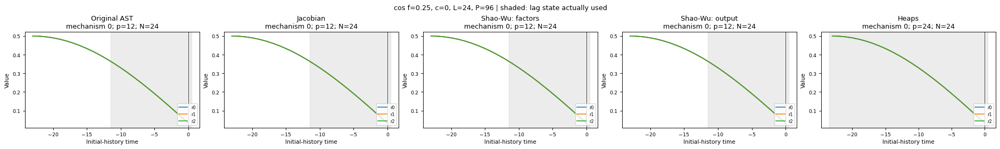

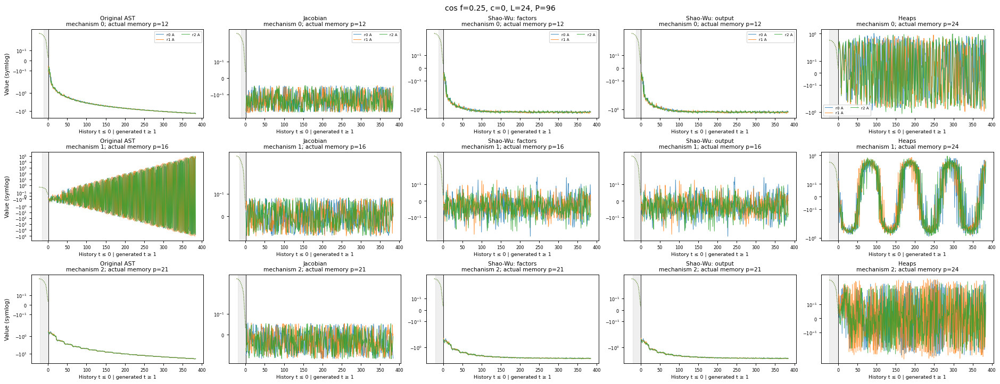

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0081
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0103
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0111
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0112
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0460


In [23]:
result = show_condition('cos f=0.25, c=0, L=24, P=96', HistorySpec('cos f=0.25, c=0, L=24, P=96', 'cosine', .5, 0.0, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=192: histórico de 48 amostras

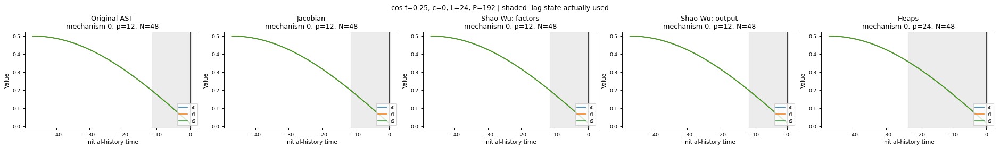

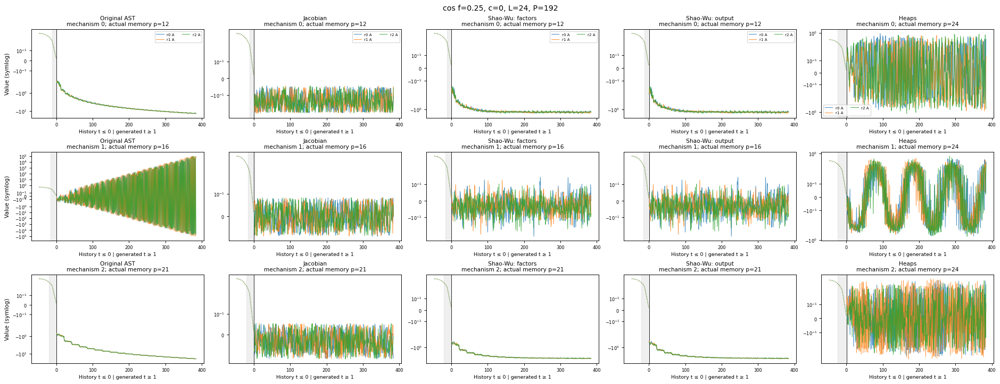

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0148
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0155
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0133
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0123
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0363


In [24]:
result = show_condition('cos f=0.25, c=0, L=24, P=192', HistorySpec('cos f=0.25, c=0, L=24, P=192', 'cosine', .5, 0.0, 192, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

### Memória até 48 passos

As ASTs usam lags entre 24 e 48; Heaps tem ordem 48. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=192: histórico de 48 amostras

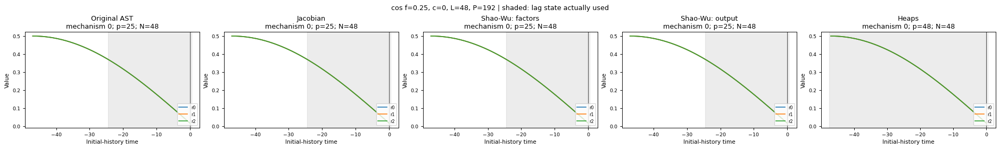

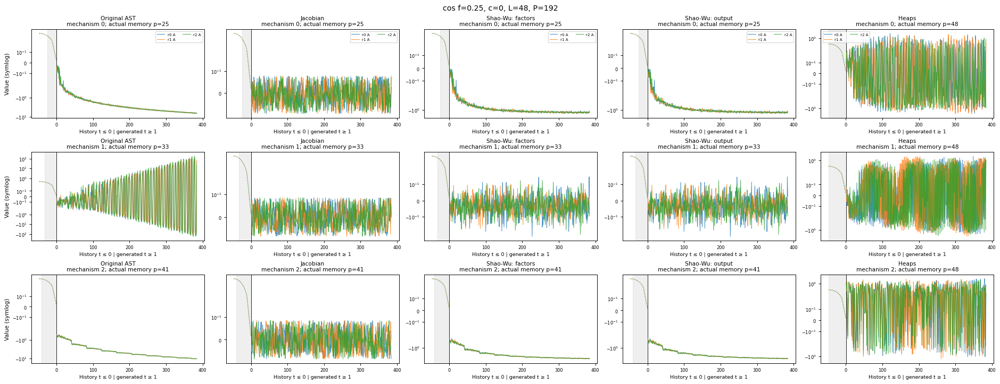

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,16.6667,8.3333,11.1111,0.0000,25,48,0.0138
5,Jacobian,36,0.0000,100.0000,100.0000,0.0000,25,48,0.0136
8,Shao-Wu: factors,36,0.0000,16.6667,41.6667,13.8889,25,48,0.0204
11,Shao-Wu: output,36,0.0000,13.8889,36.1111,13.8889,25,48,0.0178
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,48,48,0.0677


In [25]:
result = show_condition('cos f=0.25, c=0, L=48, P=192', HistorySpec('cos f=0.25, c=0, L=48, P=192', 'cosine', .5, 0.0, 192, 0.25), cyclic_config(48), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=384: histórico de 96 amostras

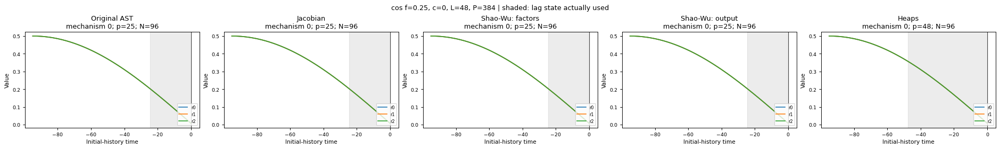

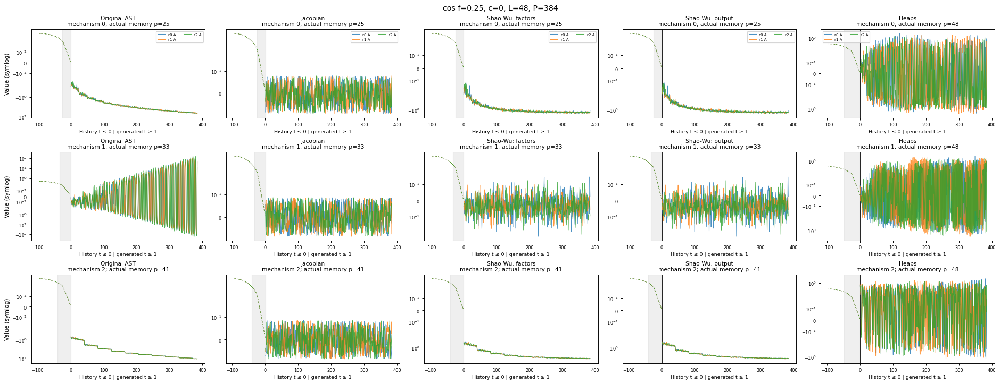

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,8.3333,8.3333,11.1111,0.0000,25,48,0.0193
5,Jacobian,36,0.0000,100.0000,100.0000,0.0000,25,48,0.0183
8,Shao-Wu: factors,36,0.0000,16.6667,38.8889,11.1111,25,48,0.0178
11,Shao-Wu: output,36,0.0000,11.1111,36.1111,11.1111,25,48,0.0140
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,48,48,0.0738


In [26]:
result = show_condition('cos f=0.25, c=0, L=48, P=384', HistorySpec('cos f=0.25, c=0, L=48, P=384', 'cosine', .5, 0.0, 384, 0.25), cyclic_config(48), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

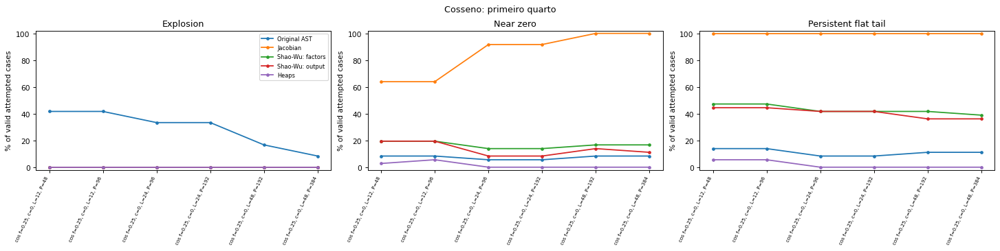

In [27]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Cosseno: primeiro quarto')
plt.show()

**O que foi feito:** Comparamos os seis pares de memória e período desta inicialização, mantendo os métodos separados nas curvas.

## 9. Cosseno: ciclo completo + escalar 0,5

Amplitude A=0,5; deslocamento c=0.5. O histórico contém 1 do ciclo, sempre com espaçamento unitário.

### Memória até 12 passos

As ASTs usam lags entre 6 e 12; Heaps tem ordem 12. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=48: histórico de 48 amostras

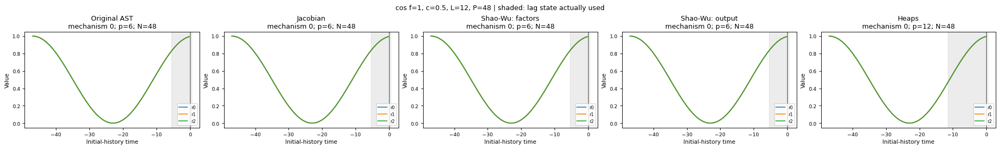

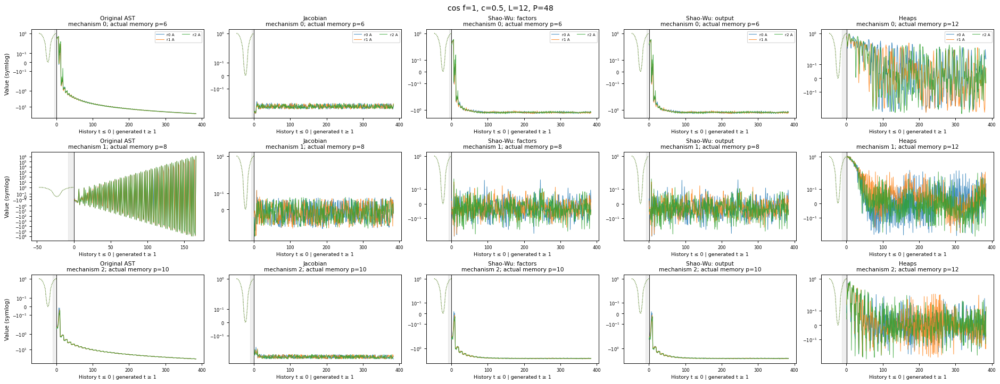

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,8.3333,13.8889,0.0000,6,12,0.0091
5,Jacobian,36,0.0000,63.8889,100.0000,25.0000,6,12,0.0142
8,Shao-Wu: factors,36,0.0000,19.4444,47.2222,16.6667,6,12,0.0116
11,Shao-Wu: output,36,0.0000,16.6667,44.4444,19.4444,6,12,0.0139
14,Heaps,36,0.0000,2.7778,5.5556,0.0000,12,12,0.0212


In [28]:
result = show_condition('cos f=1, c=0.5, L=12, P=48', HistorySpec('cos f=1, c=0.5, L=12, P=48', 'cosine', .5, 0.5, 48, 1.0), cyclic_config(12), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=96: histórico de 96 amostras

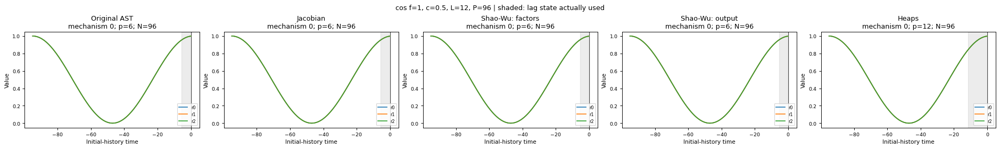

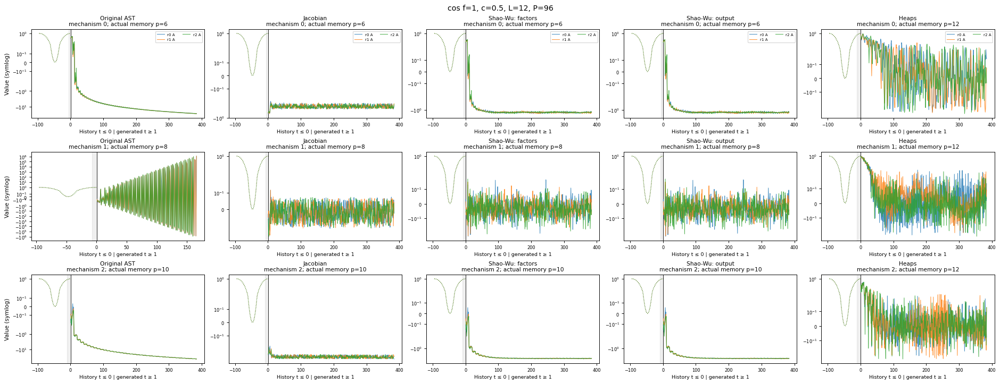

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,8.3333,13.8889,0.0000,6,12,0.0070
5,Jacobian,36,0.0000,63.8889,100.0000,25.0000,6,12,0.0122
8,Shao-Wu: factors,36,0.0000,19.4444,47.2222,16.6667,6,12,0.0107
11,Shao-Wu: output,36,0.0000,16.6667,44.4444,19.4444,6,12,0.0116
14,Heaps,36,0.0000,2.7778,5.5556,0.0000,12,12,0.0212


In [29]:
result = show_condition('cos f=1, c=0.5, L=12, P=96', HistorySpec('cos f=1, c=0.5, L=12, P=96', 'cosine', .5, 0.5, 96, 1.0), cyclic_config(12), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

### Memória até 24 passos

As ASTs usam lags entre 12 e 24; Heaps tem ordem 24. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=96: histórico de 96 amostras

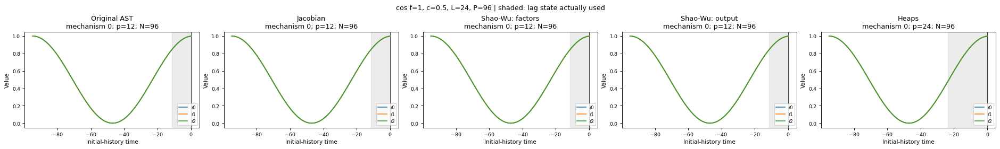

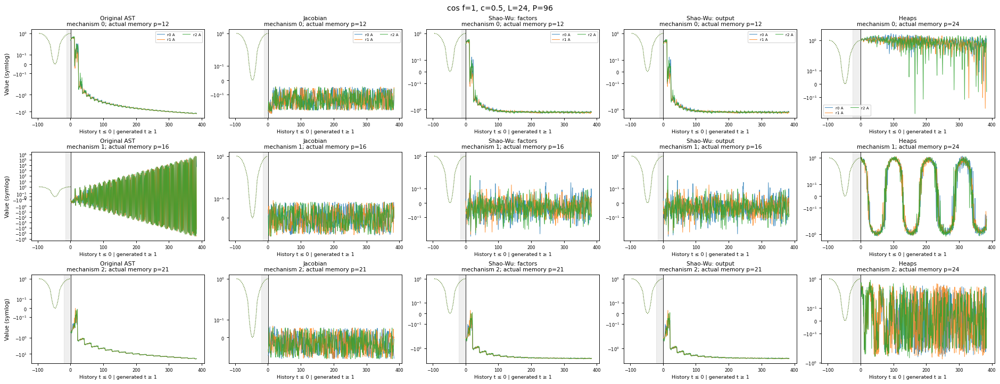

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0077
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0116
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0109
11,Shao-Wu: output,36,0.0000,8.3333,38.8889,16.6667,12,24,0.0097
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0299


In [30]:
result = show_condition('cos f=1, c=0.5, L=24, P=96', HistorySpec('cos f=1, c=0.5, L=24, P=96', 'cosine', .5, 0.5, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=192: histórico de 192 amostras

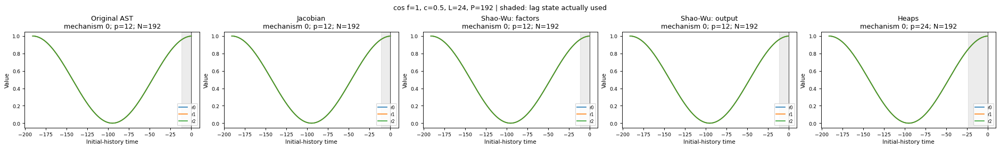

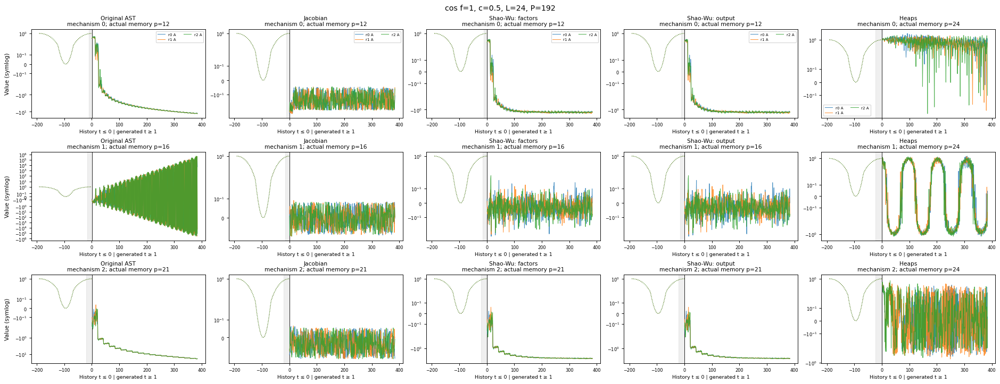

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0083
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0136
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0097
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,19.4444,12,24,0.0091
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0300


In [31]:
result = show_condition('cos f=1, c=0.5, L=24, P=192', HistorySpec('cos f=1, c=0.5, L=24, P=192', 'cosine', .5, 0.5, 192, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

### Memória até 48 passos

As ASTs usam lags entre 24 e 48; Heaps tem ordem 48. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=192: histórico de 192 amostras

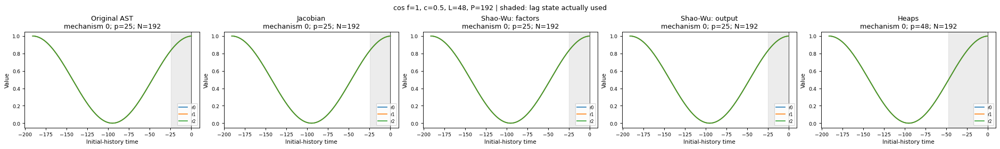

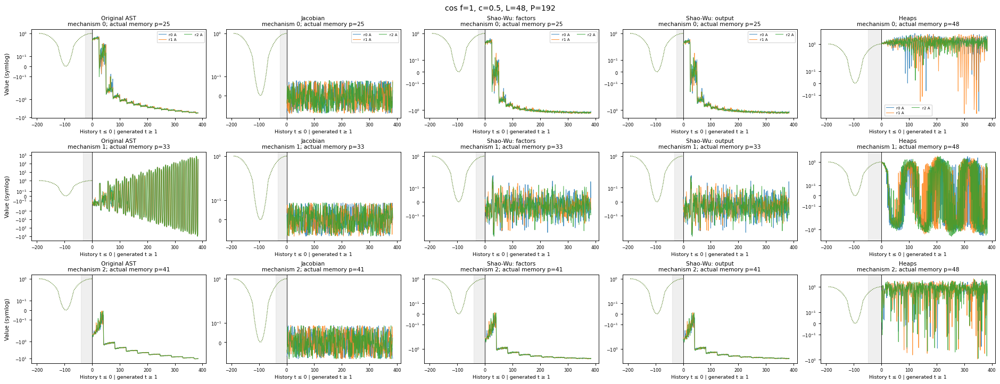

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,16.6667,8.3333,11.1111,0.0000,25,48,0.0083
5,Jacobian,36,0.0000,100.0000,100.0000,0.0000,25,48,0.0108
8,Shao-Wu: factors,36,0.0000,16.6667,36.1111,8.3333,25,48,0.0108
11,Shao-Wu: output,36,0.0000,11.1111,27.7778,8.3333,25,48,0.0122
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,48,48,0.0684


In [32]:
result = show_condition('cos f=1, c=0.5, L=48, P=192', HistorySpec('cos f=1, c=0.5, L=48, P=192', 'cosine', .5, 0.5, 192, 1.0), cyclic_config(48), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=384: histórico de 384 amostras

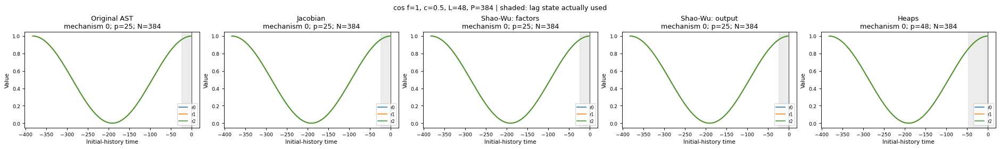

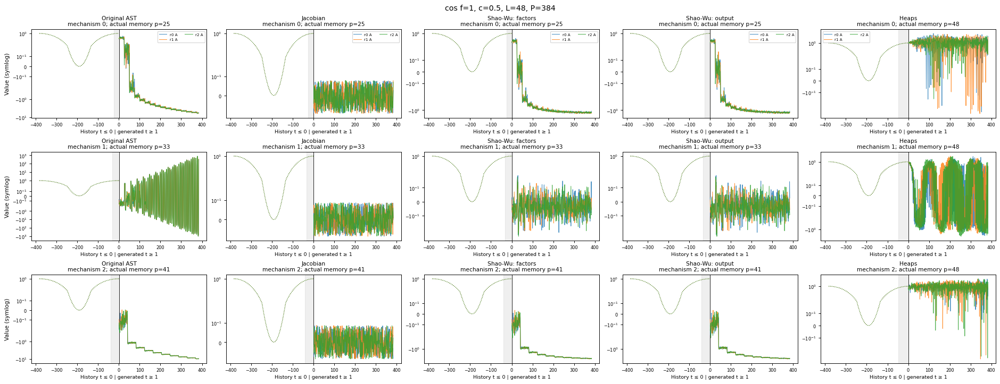

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,16.6667,8.3333,11.1111,0.0000,25,48,0.0091
5,Jacobian,36,0.0000,100.0000,100.0000,0.0000,25,48,0.0103
8,Shao-Wu: factors,36,0.0000,16.6667,36.1111,8.3333,25,48,0.0104
11,Shao-Wu: output,36,0.0000,11.1111,30.5556,11.1111,25,48,0.0093
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,48,48,0.0581


In [33]:
result = show_condition('cos f=1, c=0.5, L=48, P=384', HistorySpec('cos f=1, c=0.5, L=48, P=384', 'cosine', .5, 0.5, 384, 1.0), cyclic_config(48), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

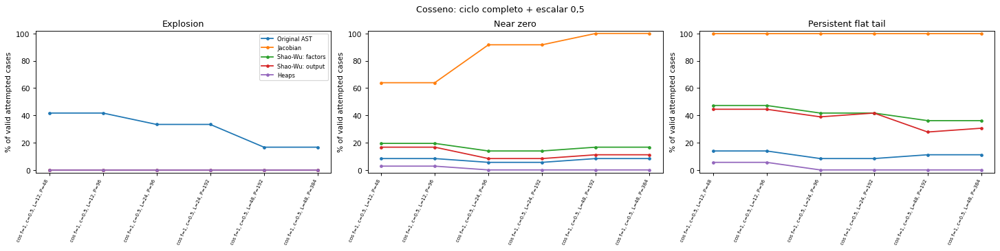

In [34]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Cosseno: ciclo completo + escalar 0,5')
plt.show()

**O que foi feito:** Comparamos os seis pares de memória e período desta inicialização, mantendo os métodos separados nas curvas.

## 10. Cosseno: primeira metade + escalar 0,5

Amplitude A=0,5; deslocamento c=0.5. O histórico contém 0.5 do ciclo, sempre com espaçamento unitário.

### Memória até 12 passos

As ASTs usam lags entre 6 e 12; Heaps tem ordem 12. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=48: histórico de 24 amostras

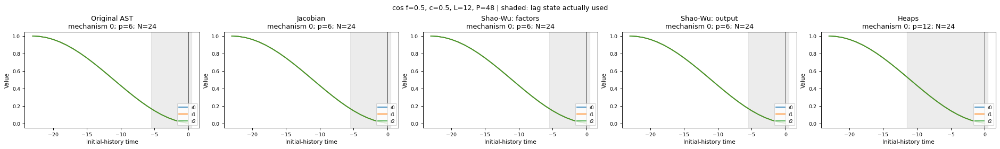

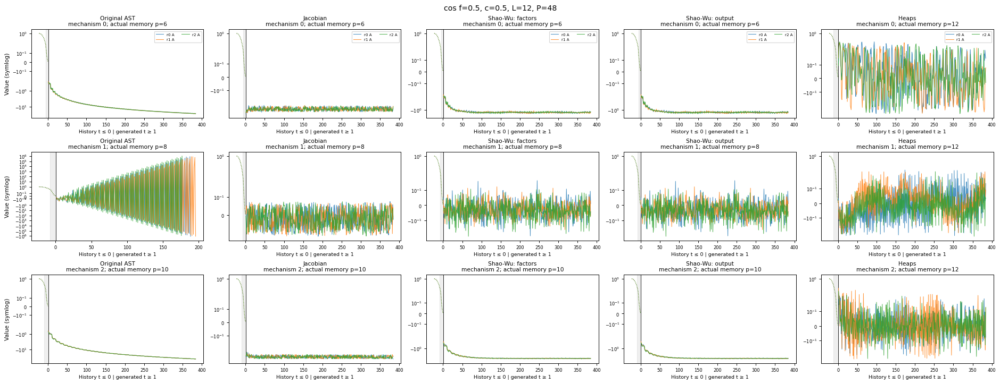

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,8.3333,13.8889,0.0000,6,12,0.0073
5,Jacobian,36,0.0000,63.8889,100.0000,25.0000,6,12,0.0159
8,Shao-Wu: factors,36,0.0000,19.4444,47.2222,16.6667,6,12,0.0124
11,Shao-Wu: output,36,0.0000,19.4444,44.4444,16.6667,6,12,0.0101
14,Heaps,36,0.0000,5.5556,5.5556,0.0000,12,12,0.0200


In [35]:
result = show_condition('cos f=0.5, c=0.5, L=12, P=48', HistorySpec('cos f=0.5, c=0.5, L=12, P=48', 'cosine', .5, 0.5, 48, 0.5), cyclic_config(12), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=96: histórico de 48 amostras

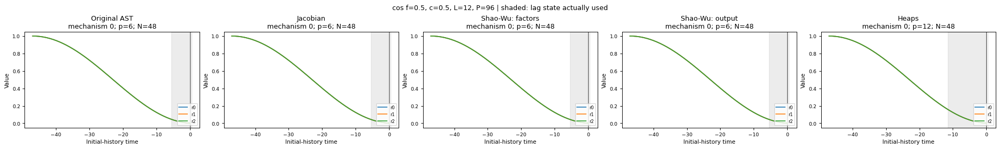

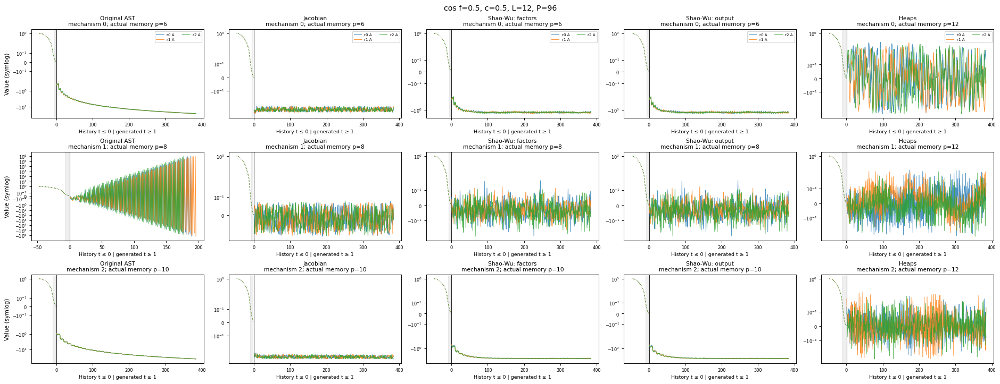

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,8.3333,13.8889,0.0000,6,12,0.0066
5,Jacobian,36,0.0000,63.8889,100.0000,25.0000,6,12,0.0108
8,Shao-Wu: factors,36,0.0000,19.4444,47.2222,16.6667,6,12,0.0101
11,Shao-Wu: output,36,0.0000,19.4444,44.4444,16.6667,6,12,0.0098
14,Heaps,36,0.0000,5.5556,2.7778,0.0000,12,12,0.0180


In [36]:
result = show_condition('cos f=0.5, c=0.5, L=12, P=96', HistorySpec('cos f=0.5, c=0.5, L=12, P=96', 'cosine', .5, 0.5, 96, 0.5), cyclic_config(12), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

### Memória até 24 passos

As ASTs usam lags entre 12 e 24; Heaps tem ordem 24. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=96: histórico de 48 amostras

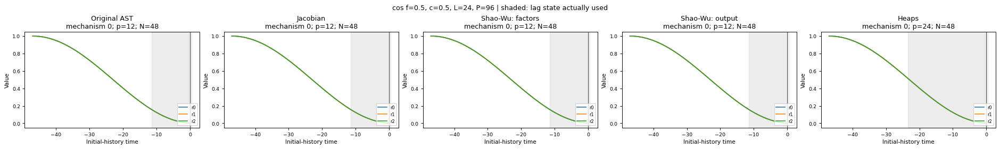

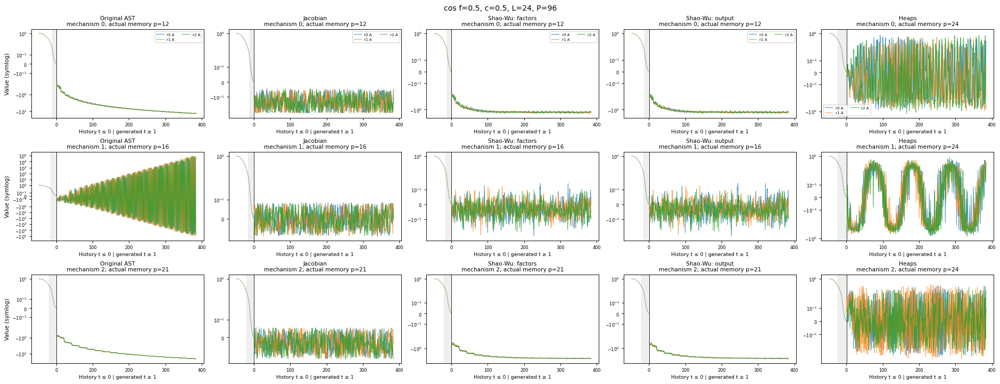

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0083
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0136
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0103
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0105
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0383


In [37]:
result = show_condition('cos f=0.5, c=0.5, L=24, P=96', HistorySpec('cos f=0.5, c=0.5, L=24, P=96', 'cosine', .5, 0.5, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=192: histórico de 96 amostras

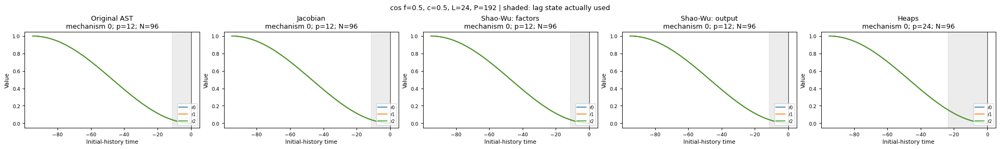

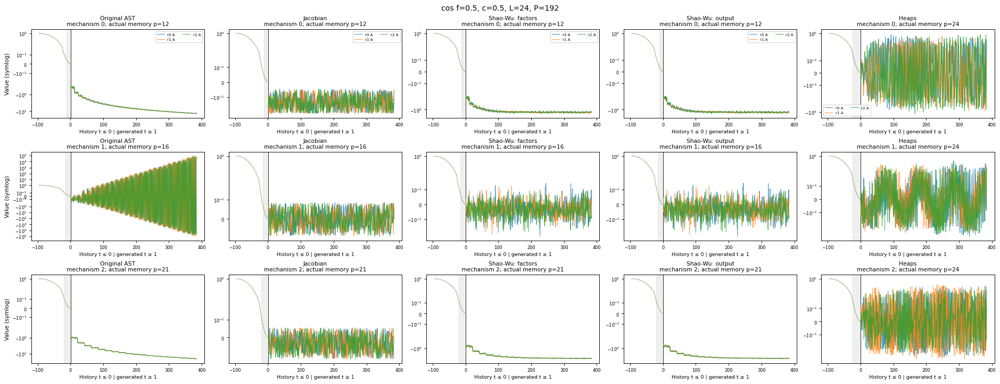

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0096
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0118
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0133
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0153
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0368


In [38]:
result = show_condition('cos f=0.5, c=0.5, L=24, P=192', HistorySpec('cos f=0.5, c=0.5, L=24, P=192', 'cosine', .5, 0.5, 192, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

### Memória até 48 passos

As ASTs usam lags entre 24 e 48; Heaps tem ordem 48. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=192: histórico de 96 amostras

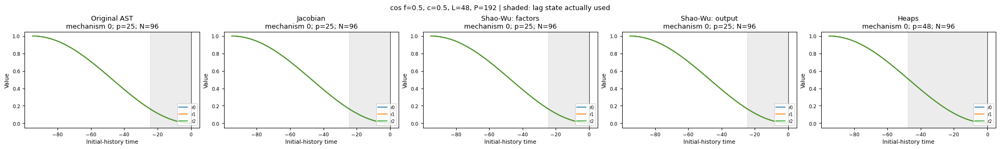

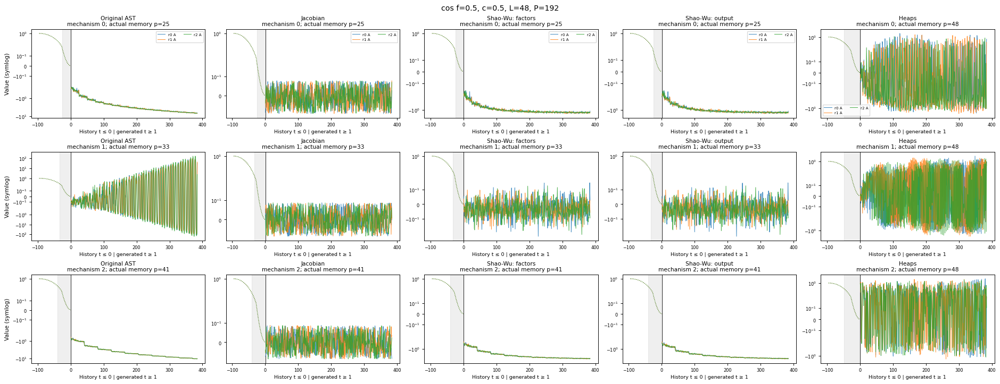

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,8.3333,8.3333,11.1111,0.0000,25,48,0.0113
5,Jacobian,36,0.0000,100.0000,100.0000,0.0000,25,48,0.0134
8,Shao-Wu: factors,36,0.0000,16.6667,38.8889,11.1111,25,48,0.0165
11,Shao-Wu: output,36,0.0000,11.1111,36.1111,11.1111,25,48,0.0206
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,48,48,0.0574


In [39]:
result = show_condition('cos f=0.5, c=0.5, L=48, P=192', HistorySpec('cos f=0.5, c=0.5, L=48, P=192', 'cosine', .5, 0.5, 192, 0.5), cyclic_config(48), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=384: histórico de 192 amostras

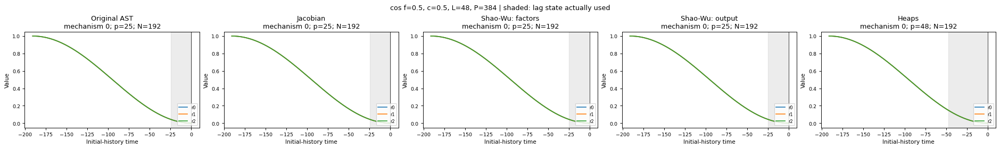

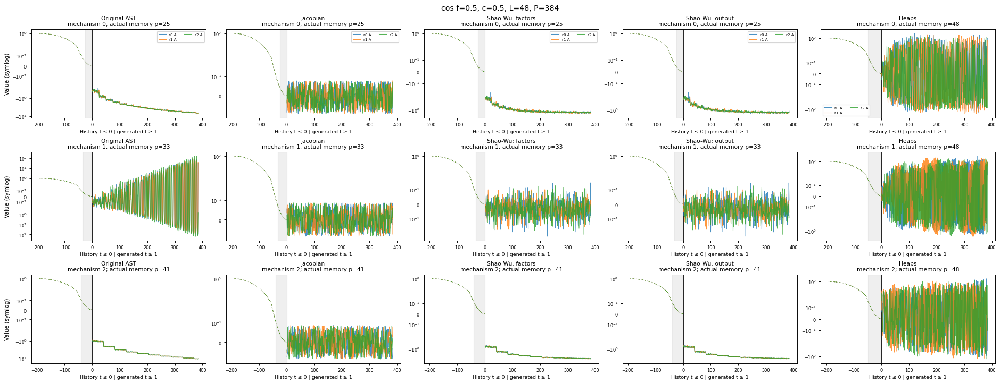

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,8.3333,8.3333,11.1111,0.0000,25,48,0.0111
5,Jacobian,36,0.0000,100.0000,100.0000,0.0000,25,48,0.0124
8,Shao-Wu: factors,36,0.0000,16.6667,36.1111,8.3333,25,48,0.0164
11,Shao-Wu: output,36,0.0000,11.1111,33.3333,8.3333,25,48,0.0122
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,48,48,0.0599


In [40]:
result = show_condition('cos f=0.5, c=0.5, L=48, P=384', HistorySpec('cos f=0.5, c=0.5, L=48, P=384', 'cosine', .5, 0.5, 384, 0.5), cyclic_config(48), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

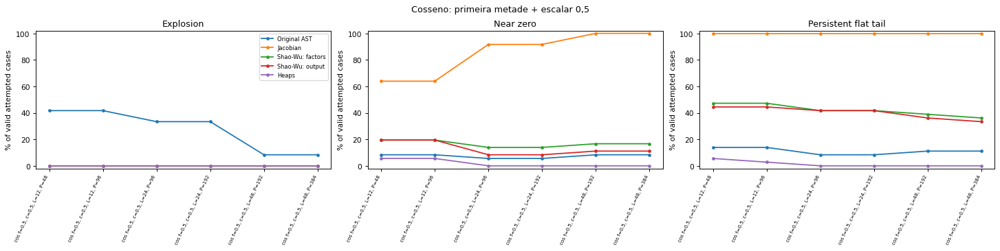

In [41]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Cosseno: primeira metade + escalar 0,5')
plt.show()

**O que foi feito:** Comparamos os seis pares de memória e período desta inicialização, mantendo os métodos separados nas curvas.

## 11. Cosseno: primeiro quarto + escalar 0,5

Amplitude A=0,5; deslocamento c=0.5. O histórico contém 0.25 do ciclo, sempre com espaçamento unitário.

### Memória até 12 passos

As ASTs usam lags entre 6 e 12; Heaps tem ordem 12. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=48: histórico de 12 amostras

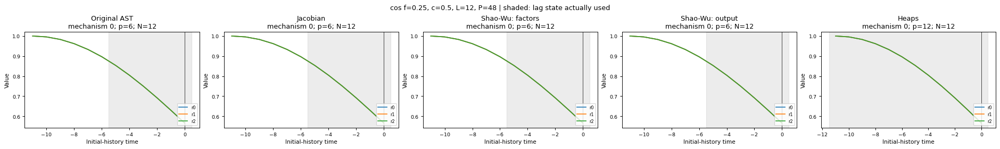

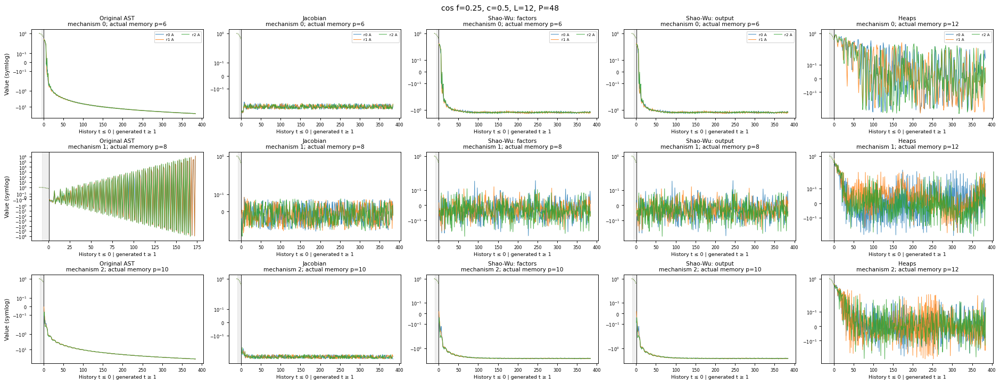

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,8.3333,13.8889,0.0000,6,12,0.0074
5,Jacobian,36,0.0000,63.8889,100.0000,25.0000,6,12,0.0124
8,Shao-Wu: factors,36,0.0000,19.4444,47.2222,16.6667,6,12,0.0119
11,Shao-Wu: output,36,0.0000,16.6667,44.4444,19.4444,6,12,0.0116
14,Heaps,36,0.0000,2.7778,5.5556,0.0000,12,12,0.0221


In [42]:
result = show_condition('cos f=0.25, c=0.5, L=12, P=48', HistorySpec('cos f=0.25, c=0.5, L=12, P=48', 'cosine', .5, 0.5, 48, 0.25), cyclic_config(12), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=96: histórico de 24 amostras

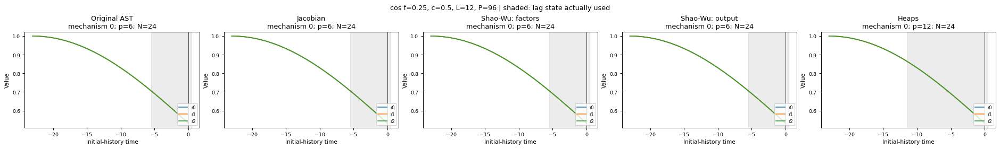

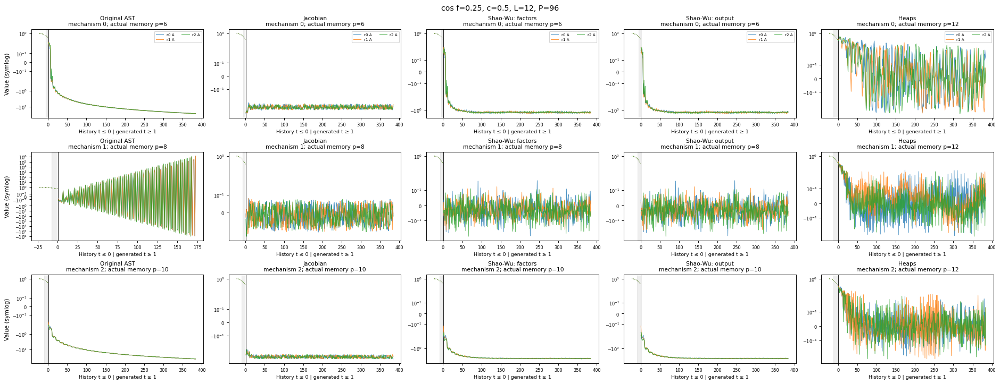

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,8.3333,13.8889,0.0000,6,12,0.0075
5,Jacobian,36,0.0000,63.8889,100.0000,25.0000,6,12,0.0117
8,Shao-Wu: factors,36,0.0000,19.4444,47.2222,16.6667,6,12,0.0116
11,Shao-Wu: output,36,0.0000,19.4444,44.4444,16.6667,6,12,0.0109
14,Heaps,36,0.0000,2.7778,5.5556,0.0000,12,12,0.0212


In [43]:
result = show_condition('cos f=0.25, c=0.5, L=12, P=96', HistorySpec('cos f=0.25, c=0.5, L=12, P=96', 'cosine', .5, 0.5, 96, 0.25), cyclic_config(12), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

### Memória até 24 passos

As ASTs usam lags entre 12 e 24; Heaps tem ordem 24. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=96: histórico de 24 amostras

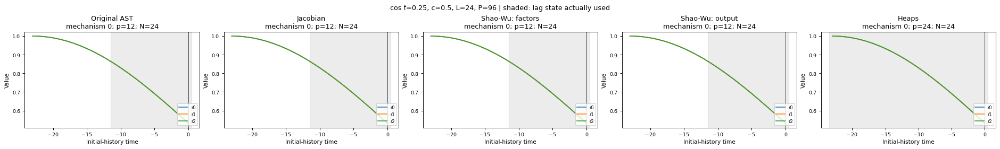

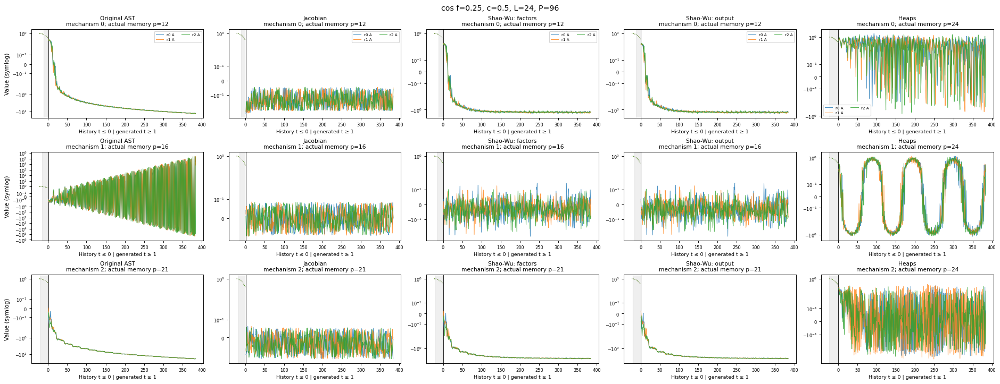

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0089
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0118
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0112
11,Shao-Wu: output,36,0.0000,8.3333,36.1111,13.8889,12,24,0.0118
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0349


In [44]:
result = show_condition('cos f=0.25, c=0.5, L=24, P=96', HistorySpec('cos f=0.25, c=0.5, L=24, P=96', 'cosine', .5, 0.5, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=192: histórico de 48 amostras

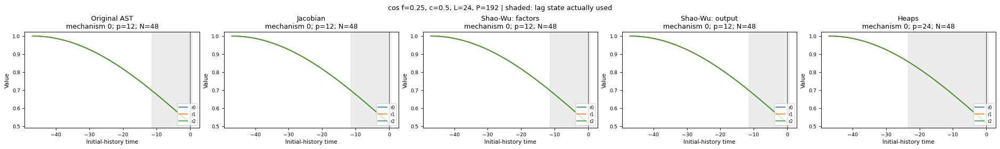

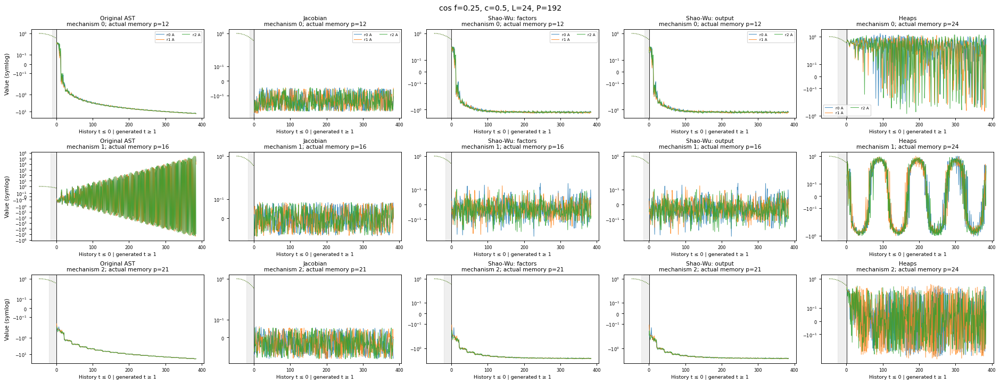

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0093
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0131
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0118
11,Shao-Wu: output,36,0.0000,8.3333,36.1111,13.8889,12,24,0.0115
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0334


In [45]:
result = show_condition('cos f=0.25, c=0.5, L=24, P=192', HistorySpec('cos f=0.25, c=0.5, L=24, P=192', 'cosine', .5, 0.5, 192, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

### Memória até 48 passos

As ASTs usam lags entre 24 e 48; Heaps tem ordem 48. Abaixo variamos o período mantendo este banco de mecanismos.

#### Período P=192: histórico de 48 amostras

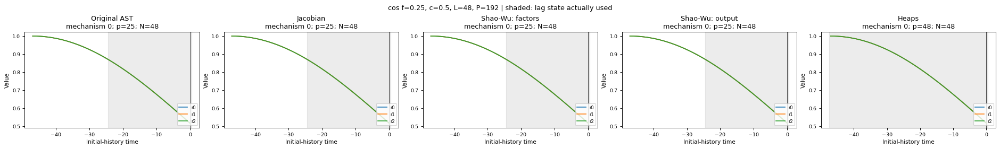

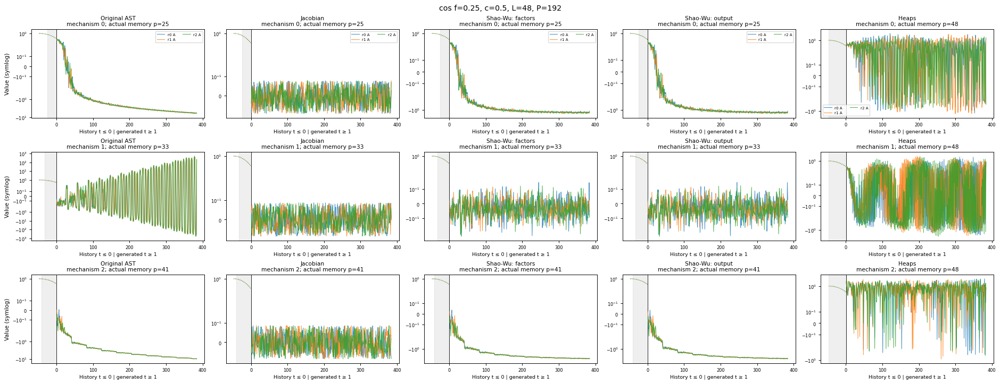

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,16.6667,8.3333,11.1111,0.0000,25,48,0.0100
5,Jacobian,36,0.0000,100.0000,100.0000,0.0000,25,48,0.0118
8,Shao-Wu: factors,36,0.0000,16.6667,41.6667,11.1111,25,48,0.0121
11,Shao-Wu: output,36,0.0000,11.1111,33.3333,11.1111,25,48,0.0112
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,48,48,0.0652


In [46]:
result = show_condition('cos f=0.25, c=0.5, L=48, P=192', HistorySpec('cos f=0.25, c=0.5, L=48, P=192', 'cosine', .5, 0.5, 192, 0.25), cyclic_config(48), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

#### Período P=384: histórico de 96 amostras

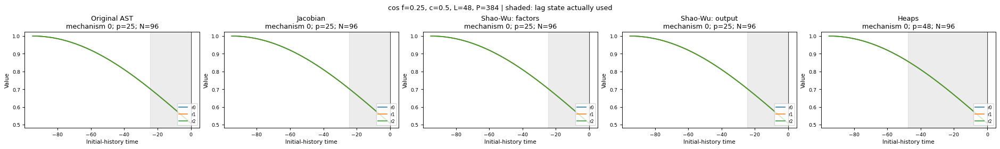

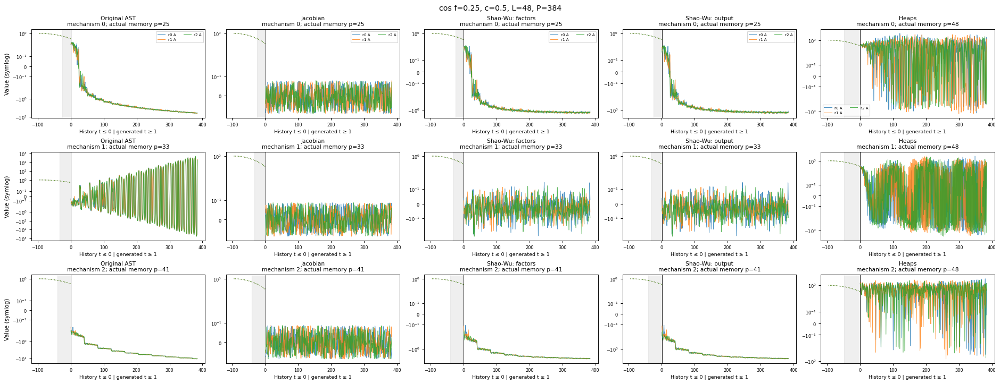

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,16.6667,8.3333,11.1111,0.0000,25,48,0.0110
5,Jacobian,36,0.0000,100.0000,100.0000,0.0000,25,48,0.0124
8,Shao-Wu: factors,36,0.0000,16.6667,36.1111,8.3333,25,48,0.0114
11,Shao-Wu: output,36,0.0000,11.1111,27.7778,8.3333,25,48,0.0109
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,48,48,0.0589


In [47]:
result = show_condition('cos f=0.25, c=0.5, L=48, P=384', HistorySpec('cos f=0.25, c=0.5, L=48, P=384', 'cosine', .5, 0.5, 384, 0.25), cyclic_config(48), overview=False)

**O que foi feito:** O gráfico em escala linear evidencia o recorte do cosseno e o deslocamento vertical. A grade mostra a continuação gerada e a tabela compara as taxas no horizonte 384.

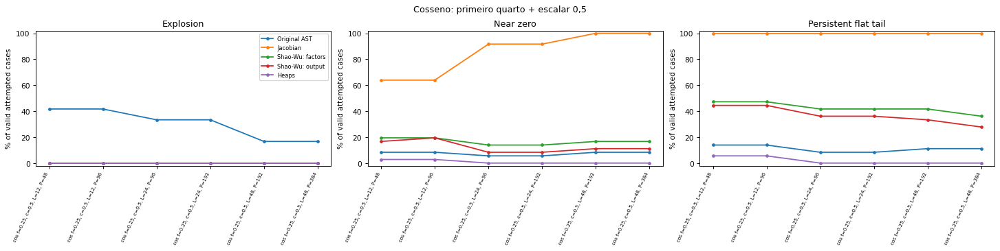

In [48]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Cosseno: primeiro quarto + escalar 0,5')
plt.show()

**O que foi feito:** Comparamos os seis pares de memória e período desta inicialização, mantendo os métodos separados nas curvas.

## Resultados consolidados: tabelas por horizonte

Cada linha conserva seu tipo de inicialização, método e tamanho de amostra. As condições não aplicáveis aparecem em tabela própria. Os tempos de simulação referem-se à chamada completa de até 384 passos, com parada na primeira explosão.

In [49]:
pd.set_option("display.max_rows", None)
FINAL_COLUMNS = ['block', 'method', 'trajectories', 'explosions', 'explosions_pct', 'near_zero_pct', 'persistent_flat_pct', 'flat_nonzero_pct', 'amplitude_decline_pct', 'minimum_actual_lag', 'maximum_actual_lag', 'mean_initialization_seconds', 'mean_simulation_seconds']
SUMMARY = pd.concat(SUMMARY_BLOCKS, ignore_index=True)
SKIPPED = pd.concat(SKIPPED_BLOCKS, ignore_index=True) if SKIPPED_BLOCKS else pd.DataFrame()
for horizon in CONFIG.horizons:
    display(Markdown(f"### Horizonte {horizon}"))
    columns = FINAL_COLUMNS
    display(SUMMARY.loc[SUMMARY.horizon == horizon, columns].round(4))
display(Markdown("### Condições fora do domínio de aplicação"))
if SKIPPED.empty:
    display(Markdown("Todas as condições declaradas foram executadas."))
else:
    display(SKIPPED.groupby(["block", "method", "reason"], sort=False).skipped_trajectories.sum().reset_index())


### Horizonte 96

,block,method,trajectories,explosions,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,amplitude_decline_pct,minimum_actual_lag,maximum_actual_lag,mean_initialization_seconds,mean_simulation_seconds
0,Histórico zero,Original AST,96,20,20.8333,13.5417,17.7083,0.0000,0.0000,1,12,0.0000,0.0065
3,Histórico zero,Jacobian,96,0,0.0000,44.7917,98.9583,36.4583,0.0000,1,12,0.0000,0.0120
6,Histórico zero,Shao-Wu: factors,96,0,0.0000,17.7083,47.9167,19.7917,0.0000,1,12,0.0000,0.0115
9,Histórico zero,Shao-Wu: output,96,0,0.0000,17.7083,46.8750,22.9167,0.0000,1,12,0.0000,0.0091
12,Histórico zero,Heaps,96,0,0.0000,38.5417,38.5417,0.0000,0.0000,1,12,0.0000,0.0121
15,Constante positiva,Original AST,96,22,22.9167,13.5417,17.7083,0.0000,3.1250,1,12,0.0000,0.0047
18,Constante positiva,Jacobian,96,0,0.0000,44.7917,98.9583,36.4583,1.0417,1,12,0.0000,0.0087
21,Constante positiva,Shao-Wu: factors,96,0,0.0000,16.6667,43.7500,16.6667,2.0833,1,12,0.0000,0.0084
24,Constante positiva,Shao-Wu: output,96,0,0.0000,15.6250,41.6667,19.7917,4.1667,1,12,0.0000,0.0085
27,Constante positiva,Heaps,96,0,0.0000,36.4583,36.4583,0.0000,25.0000,1,12,0.0000,0.0127


### Horizonte 192

,block,method,trajectories,explosions,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,amplitude_decline_pct,minimum_actual_lag,maximum_actual_lag,mean_initialization_seconds,mean_simulation_seconds
1,Histórico zero,Original AST,96,47,48.9583,11.4583,16.6667,2.0833,0.0000,1,12,0.0000,0.0065
4,Histórico zero,Jacobian,96,0,0.0000,45.8333,97.9167,33.3333,0.0000,1,12,0.0000,0.0120
7,Histórico zero,Shao-Wu: factors,96,0,0.0000,23.9583,61.4583,27.0833,0.0000,1,12,0.0000,0.0115
10,Histórico zero,Shao-Wu: output,96,0,0.0000,19.7917,58.3333,30.2083,0.0000,1,12,0.0000,0.0091
13,Histórico zero,Heaps,96,0,0.0000,35.4167,37.5000,0.0000,1.0417,1,12,0.0000,0.0121
16,Constante positiva,Original AST,96,47,48.9583,11.4583,16.6667,2.0833,3.1250,1,12,0.0000,0.0047
19,Constante positiva,Jacobian,96,0,0.0000,45.8333,97.9167,33.3333,1.0417,1,12,0.0000,0.0087
22,Constante positiva,Shao-Wu: factors,96,0,0.0000,23.9583,61.4583,27.0833,10.4167,1,12,0.0000,0.0084
25,Constante positiva,Shao-Wu: output,96,0,0.0000,20.8333,58.3333,30.2083,10.4167,1,12,0.0000,0.0085
28,Constante positiva,Heaps,96,0,0.0000,37.5000,37.5000,1.0417,21.8750,1,12,0.0000,0.0127


### Horizonte 384

,block,method,trajectories,explosions,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,amplitude_decline_pct,minimum_actual_lag,maximum_actual_lag,mean_initialization_seconds,mean_simulation_seconds
2,Histórico zero,Original AST,96,47,48.9583,10.4167,15.6250,0.0000,0.0000,1,12,0.0000,0.0065
5,Histórico zero,Jacobian,96,0,0.0000,46.8750,100.0000,35.4167,0.0000,1,12,0.0000,0.0120
8,Histórico zero,Shao-Wu: factors,96,0,0.0000,18.7500,59.3750,27.0833,0.0000,1,12,0.0000,0.0115
11,Histórico zero,Shao-Wu: output,96,0,0.0000,16.6667,56.2500,30.2083,0.0000,1,12,0.0000,0.0091
14,Histórico zero,Heaps,96,0,0.0000,38.5417,38.5417,0.0000,0.0000,1,12,0.0000,0.0121
17,Constante positiva,Original AST,96,47,48.9583,10.4167,15.6250,0.0000,1.0417,1,12,0.0000,0.0047
20,Constante positiva,Jacobian,96,0,0.0000,46.8750,100.0000,35.4167,2.0833,1,12,0.0000,0.0087
23,Constante positiva,Shao-Wu: factors,96,0,0.0000,18.7500,59.3750,27.0833,4.1667,1,12,0.0000,0.0084
26,Constante positiva,Shao-Wu: output,96,0,0.0000,16.6667,56.2500,30.2083,4.1667,1,12,0.0000,0.0085
29,Constante positiva,Heaps,96,0,0.0000,38.5417,38.5417,0.0000,22.9167,1,12,0.0000,0.0127


### Condições fora do domínio de aplicação

,block,method,reason,skipped_trajectories
0,Distribuição estacionária conjunta,Original AST,Joint stationary initializer unavailable,96
1,Distribuição estacionária conjunta,Jacobian,Joint stationary initializer unavailable,96
2,Distribuição estacionária conjunta,Shao-Wu: factors,Joint stationary initializer unavailable,96
3,Distribuição estacionária conjunta,Shao-Wu: output,Joint stationary initializer unavailable,96


**O que foi feito:** Reunimos as métricas de todos os casos executados, sem somar grupos com condições diferentes. As exclusões indicam limitações de aplicação do método.

### Registro completo do experimento

Esta única célula reúne pergunta, hipótese, configurações, fórmulas, sementes, proveniência, métricas, síntese científica e comando de reprodução.

In [50]:
import os
def git_output(*args):
    return subprocess.check_output(["git", *args], cwd=ROOT, text=True).strip()

last = SUMMARY[SUMMARY.horizon == max(CONFIG.horizons)]
metrics = ["pair_explosion_pct", "forgotten_pct_all_pairs"] if STUDY == "forgetting" else [
    "explosions_pct", "near_zero_pct", "persistent_flat_pct"]
lines = []
for method, block in last.groupby("method", sort=False):
    values = "; ".join(f"{m}: {block[m].min():.2f}% a {block[m].max():.2f}%" for m in metrics)
    lines.append(f"- **{method}:** {values}.")
scientific_summary = "\n".join(lines) + (
    "\n\nOs intervalos acima são mínimos e máximos descritivos entre condições. "
    "Os resultados usam todos os casos executados, inclusive explosões; condições fora do domínio "
    "ficam listadas separadamente. Históricos cíclicos mudam o estado inicial, enquanto as equações "
    "determinam a continuação. A comparação de lags também reflete as diferentes construções "
    "dos mecanismos. Os padrões empíricos valem para as sementes, bancos e horizontes declarados."
)
source_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in sorted((ROOT / "src" / "tsfmxai").rglob("*.py"))}
record = {
    "research_question": QUESTION,
    "hypothesis": HYPOTHESIS,
    "design": "Cada seção é um tipo de inicialização; dentro dela comparamos as quatro famílias (cinco variantes).",
    "conditions": DECLARATIONS,
    "generator_banks": [{"configuration": asdict(c),
                         "generator_configurations": {g: asdict(v) for g, v in generator_configs(c).items()},
                         "formulas": {g: [m.formulas if hasattr(m, 'formulas') else [m.formula]
                                           for m in mechanisms] for g, mechanisms in banks.items()}}
                        for c, banks in BANKS.items()],
    "seeds": {"mechanism_root": CONFIG.mechanism_seed, "trajectory_root": CONFIG.trajectory_seed,
              "mechanisms": "derive_sample_seed(mechanism_root, index)",
              "streams": "SeedSequence([trajectory_root, mechanism_index, trajectory_index]).spawn(3)",
              "stream_names": ["unit_history", "future_innovations", "stationary_history"],
              "pairing": "Exact future innovation arrays reused across conditions within each mechanism/trajectory."},
    "provenance": {"source_sha256": source_hashes, "python": sys.version, "platform": platform.platform(),
                   "packages": {p: importlib.metadata.version(p) for p in ("numpy", "pandas", "matplotlib", "nbformat", "nbclient")},
                   "numerical_threads": 1, "execution_schedule": os.environ.get("TSFMXAI_EXECUTION_SCHEDULE", "Not specified by runner")},
    "metrics": json.loads(SUMMARY.to_json(orient="records")),
    "unsupported_cases": json.loads(SKIPPED.to_json(orient="records")),
    "scientific_summary": scientific_summary,
    "reproduction_command_from_repository_root": (
        ".venv/Scripts/python.exe -m jupyter nbconvert --to notebook --execute --inplace "
        f"experiments/time_series_initialization/{NOTEBOOK_NAME} --ExecutePreprocessor.timeout=3600"),
    "references": ["Heaps (2023): https://arxiv.org/pdf/2004.09455",
                   "Shao and Wu (2007), Theorem 5.1: https://arxiv.org/pdf/math/0611029",
                   "Project report, generator-specific guarantees and startup restrictions."],
}
display(Markdown("**Síntese científica desta execução**\n\n" + scientific_summary))
display(JSON(record, expanded=False))


**Síntese científica desta execução**

- **Original AST:** explosions_pct: 8.33% a 50.00%; near_zero_pct: 5.56% a 10.42%; persistent_flat_pct: 8.33% a 15.62%.
- **Jacobian:** explosions_pct: 0.00% a 0.00%; near_zero_pct: 46.88% a 100.00%; persistent_flat_pct: 100.00% a 100.00%.
- **Shao-Wu: factors:** explosions_pct: 0.00% a 0.00%; near_zero_pct: 13.89% a 19.44%; persistent_flat_pct: 36.11% a 59.38%.
- **Shao-Wu: output:** explosions_pct: 0.00% a 0.00%; near_zero_pct: 8.33% a 19.44%; persistent_flat_pct: 27.78% a 56.25%.
- **Heaps:** explosions_pct: 0.00% a 0.00%; near_zero_pct: 0.00% a 38.54%; persistent_flat_pct: 0.00% a 38.54%.

Os intervalos acima são mínimos e máximos descritivos entre condições. Os resultados usam todos os casos executados, inclusive explosões; condições fora do domínio ficam listadas separadamente. Históricos cíclicos mudam o estado inicial, enquanto as equações determinam a continuação. A comparação de lags também reflete as diferentes construções dos mecanismos. Os padrões empíricos valem para as sementes, bancos e horizontes declarados.

<IPython.core.display.JSON object>

**O que foi feito:** O registro permite reproduzir a execução e recuperar as condições exatas que produziram cada linha da tabela. Todos os resultados ficam neste notebook.